# SO, this is a notbook in which i was testing stuff...

## It's messy, i am not sure everytg=hing still runs ahaha

but basically what i did was:
- try multiple representations, first naively, a single mbhb + noise + gb, then in batches. at some point i noticed i had a wrap around problem and copied the cell adjusting it in all of the sections ahah
- this for stft, scattering, superlet, sqeezypy, look at the file outline, maybe it's easier to understan the structure... i just copied some cells over and over changing the rpepresentation


# Test torch STFT representation

In [1]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft, windows
import scipy.signal as signal

from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import YRSID_SI, PC_SI 
from gbgpu.gbgpu import GBGPU
from gwpy.timeseries import TimeSeries

from kymatio.numpy import Scattering1D

dt = 10.0                       
fs = 1.0 / dt                   
Tobs = 2 * 24 * 3600            

N = 2**int(np.floor(np.log2(Tobs / dt)))
Tobs = N * dt                   
df = 1.0 / Tobs
t = np.arange(N) * dt
freqs_fft = np.fft.rfftfreq(N, dt)

print(f"Observation: {Tobs/3600:.1f} hours")
print(f"Points (N): {N}")
print(f"Nyquist Freq: {fs/2:.2f} Hz")

LOG: [fix_cupy] Attempting to patch CuPy...
LOG: [fix_cupy] CuPy not installed. Skipping patch.


ModuleNotFoundError: No module named 'bbhx'

In [2]:
wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))

m1, m2 = 6e5, 1e6
t_ref = Tobs * 0.8  
dist = 15e3 * PC_SI * 1e6
modes = [(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

wave_mbhb = wave_gen(
    m1, m2, 0.2, 0.4, dist,
    0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, t_ref,
    t_obs_start=0.0, t_obs_end=Tobs, 
    freqs=freqs_fft, modes=modes, direct=False, fill=True, length=N
)[0]

h_mbhb_td = np.fft.irfft(wave_mbhb[0], n=N)

gb = GBGPU(force_backend="cpu")

amp = np.array([3e-22, 2e-22, 8e-22])
f0 = np.array([2.0e-3, 5.5e-3, 3.0e-3])
fdot = np.array([1e-17, 1e-17, 1e-17])
zeros = np.zeros(3)
params = np.array([amp, f0, fdot, zeros, zeros, zeros+0.5, zeros, zeros, zeros])

gb.run_wave(*params, N=N, dt=dt, T=Tobs, oversample=2)
A_gb_fd = gb.A 

h_gb_fd = np.zeros_like(freqs_fft, dtype=complex)
for i in range(3):
    h_gb_fd += np.interp(freqs_fft, gb.freqs[i], A_gb_fd[i].real) + \
               1j * np.interp(freqs_fft, gb.freqs[i], A_gb_fd[i].imag)

h_gb_td = np.fft.irfft(h_gb_fd, n=N)

np.random.seed(42)
noise_amp = 1e-21 
noise = np.random.normal(0, noise_amp, N)

h_mix = h_mbhb_td + h_gb_td + noise

print("Data Generation Complete.")

Data Generation Complete.


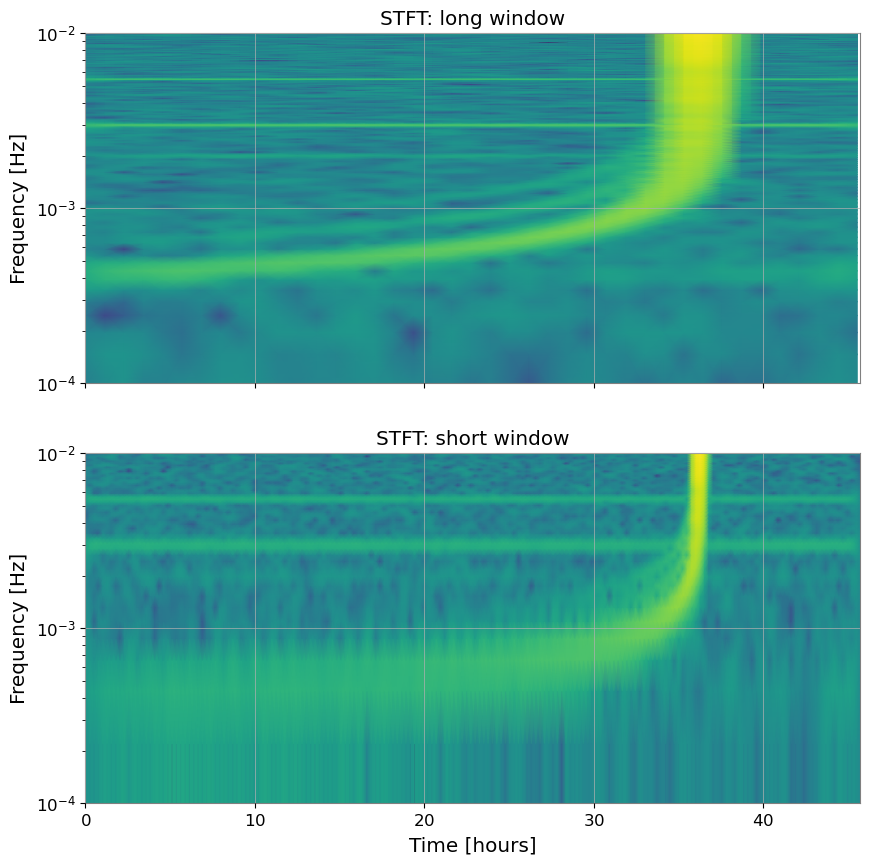

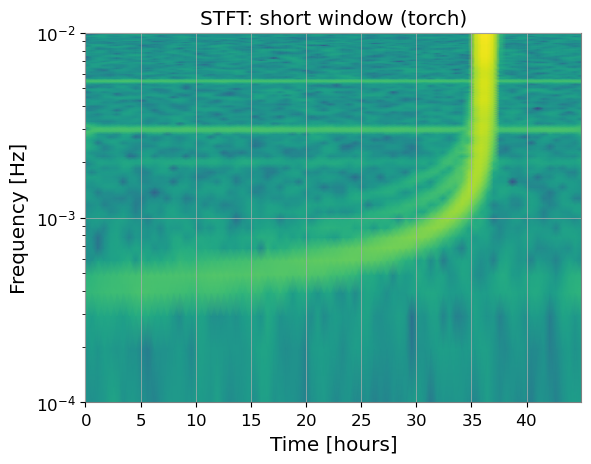

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

nperseg_long = 2048 
noverlap = nperseg_long *4/5
f_l, t_l, Z_l = stft(h_mix, fs, nperseg=nperseg_long, noverlap=noverlap)

axes[0].pcolormesh(t_l/3600, f_l, np.log10(np.abs(Z_l)), shading='gouraud', cmap='viridis')
axes[0].set_title(f"STFT: long window")
axes[0].set_ylim(1e-4, 1e-2)
axes[0].set_yscale('log')
axes[0].set_ylabel("Frequency [Hz]")

nperseg_short = 456
noverlap = nperseg_short *4/5
f_s, t_s, Z_s = stft(h_mix, fs, nperseg=nperseg_short, noverlap=noverlap)

axes[1].pcolormesh(t_s/3600, f_s, np.log10(np.abs(Z_s)), shading='gouraud', cmap='viridis')
axes[1].set_title(f"STFT: short window")
axes[1].set_ylim(1e-4, 1e-2)
axes[1].set_yscale('log')
axes[1].set_ylabel("Frequency [Hz]")
axes[1].set_xlabel("Time [hours]")

plt.show()

import torch
import numpy as np

h_torch = torch.tensor(h_mix, dtype=torch.float32)

nperseg_short = 1024
noverlap = int(nperseg_short * 4 / 5)
hop_length = nperseg_short - noverlap

window = torch.hann_window(nperseg_short)

Z_s = torch.stft(
    h_torch,
    n_fft=nperseg_short,
    hop_length=hop_length,
    window=window,
    return_complex=True
)

Z_s_mag = torch.abs(Z_s).numpy()

f_s = torch.fft.rfftfreq(nperseg_short, d=1/fs).numpy()

t_s = np.arange(Z_s.shape[1]) * hop_length / fs
plt.title("STFT: short window (torch)")
plt.ylim(1e-4, 1e-2)
plt.yscale('log')
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [hours]")

plt.pcolormesh(
    t_s/3600,
    f_s,
    np.log10(Z_s_mag),
    shading='gouraud',
    cmap='viridis'
)




## problem: wrap around!

I need to produce the signal on a bigger window ( longer than the signal !!) and then cut it to only the part i am interested in !!!!




Wanted Observation: 48.0 hours
Generation Buffer : 30.0 days (Safe Zone)
Cut MBHB shape: (17280,)


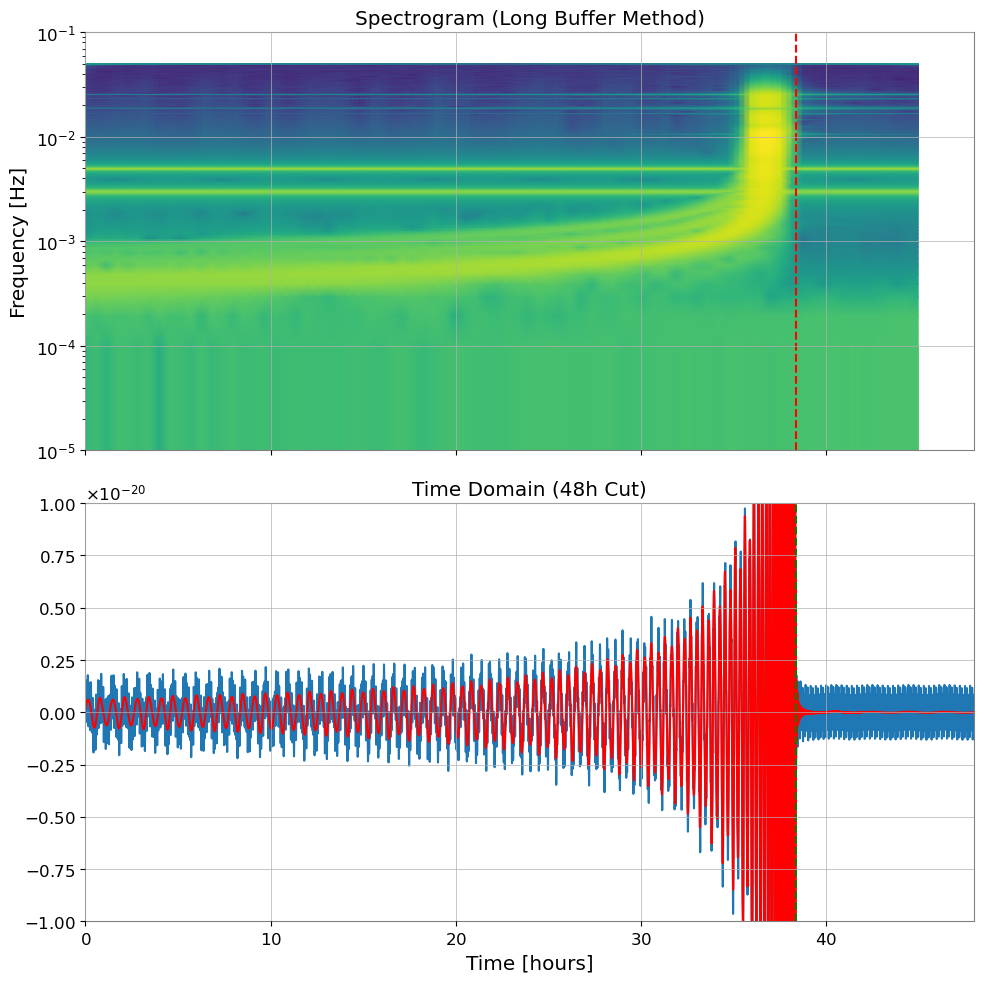

In [ ]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
import torch
from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import PC_SI
from gbgpu.gbgpu import GBGPU

dt = 10.0
fs = 1.0 / dt

T_obs = 48 * 3600            
N_obs = int(T_obs / dt)

T_gen = 30 * 24 * 3600       
N_gen = int(T_gen / dt)      

print(f"Wanted Observation: {T_obs/3600:.1f} hours")
print(f"Generation Buffer : {T_gen/86400:.1f} days (Safe Zone)")


## MBHB IS GENERATED ON A LONGER TIME SECTION TO AV OID WRAP-AROUND
wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))

m1, m2 = 6e5, 1e6
dist = 15e3 * PC_SI * 1e6
modes = [(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]
t_merger_in_long_buffer = T_gen - (T_obs * 0.2) 

freqs_long = np.fft.rfftfreq(N_gen, dt)

wave_long_fd = wave_gen(
    m1, m2, 0.2, 0.4, dist,
    0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, 
    t_merger_in_long_buffer,
    t_obs_start=0.0, t_obs_end=T_gen, 
    freqs=freqs_long, modes=modes, direct=False, fill=True, length=N_gen
)[0]

h_long_td = np.fft.irfft(wave_long_fd, n=N_gen)

# THEN I CUT IT

h_mbhb_cut = h_long_td[0, -N_obs:] 

print(f"Cut MBHB shape: {h_mbhb_cut.shape}") 

gb = GBGPU(force_backend="cpu")
gb_params = np.array([
    [3e-22, 2e-22], [3.0e-3, 5.0e-3], [1e-17, 1e-17], 
    [0,0], [0,0], [0.5,0.5], [0,0], [0,0], [0,0]
])
gb.run_wave(*gb_params, N=N_obs, dt=dt, T=T_obs, oversample=2) 

h_gb_cut = np.zeros(N_obs)
freqs_short = np.fft.rfftfreq(N_obs, dt)

for i in range(len(gb_params[0])):
    gb_fd = np.interp(freqs_short, gb.freqs[i], gb.A[i].real) + \
            1j * np.interp(freqs_short, gb.freqs[i], gb.A[i].imag)
    h_gb_cut += np.fft.irfft(gb_fd, n=N_obs)

h_mix = h_mbhb_cut + h_gb_cut

fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

h_torch = torch.tensor(h_mix, dtype=torch.float32)

nperseg = 1024
noverlap = int(nperseg * 0.8)

Z_torch = torch.stft(
    h_torch,
    n_fft=nperseg,
    hop_length=nperseg - noverlap,
    window=torch.hann_window(nperseg),
    return_complex=True,
    center=False, 
    onesided=True
)
Z_mag = torch.abs(Z_torch).numpy()

t_axis = np.arange(Z_mag.shape[1]) * (nperseg - noverlap) * dt
f_axis = torch.fft.rfftfreq(nperseg, dt).numpy()

cut = 0

axes[0].pcolormesh(t_axis/3600, f_axis[cut:], np.log10(Z_mag[cut:,:] + 1e-30), 
                   shading='gouraud', cmap='viridis')
axes[0].set_title("Spectrogram (Long Buffer Method)")
axes[0].set_ylabel("Frequency [Hz]")
axes[0].axvline((T_obs * 0.8)/3600, color='r', linestyle='--', label='Merger')
axes[0].set_yscale('log')
axes[0].set_ylim(1e-5, 1e-1)

axes[1].plot(np.arange(N_obs)*dt/3600, h_mix)
axes[1].plot(np.arange(N_obs)*dt/3600, h_mbhb_cut, color='r')

axes[1].set_title("Time Domain (48h Cut)")
axes[1].set_xlabel("Time [hours]")
axes[1].set_xlim(0, 48)
axes[1].axvline((T_obs * 0.8)/3600, color='green', linestyle='--', label='Merger')

axes[1].set_ylim(-1e-20, 1e-20)


plt.tight_layout()
plt.show()

### generating gbs.. no need for interpolation, can add them before

Using GPU (CuPy)
Running massive batch generation...
Done. Generated background from 100 binaries.


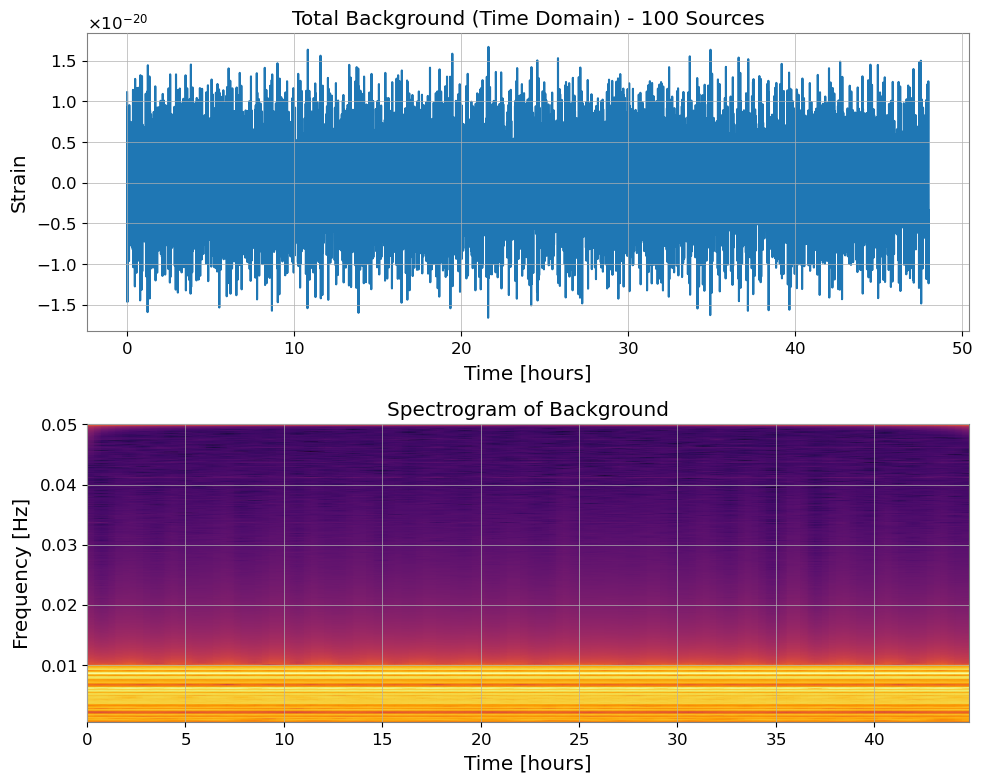

In [ ]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
from gbgpu.gbgpu import GBGPU
import torch

try:
    import cupy as cp
    xp = cp
    use_gpu = True
    print("Using GPU (CuPy)")
except ImportError:
    import numpy as xp
    use_gpu = False
    print("Using CPU (NumPy)")
import numpy as xp
use_gpu = False
dt = 10.0
T_obs = 48 * 3600            
N_obs = int(T_obs / dt)
N_freq = N_obs // 2 + 1 

n_binaries = 100  
gb_params = np.zeros((9, n_binaries))


gb_params[0] = 10**np.random.uniform(-23, -21, n_binaries) 

gb_params[1] = 10**np.random.uniform(np.log10(1e-4), np.log10(1e-2), n_binaries)   

gb_params[2] = 10**np.random.uniform(-18, -16, n_binaries)
gb_params[3] = 0.0
gb_params[4] = np.random.uniform(0, 2*np.pi, n_binaries)
gb_params[5] = np.arccos(np.random.uniform(-1, 1, n_binaries))
gb_params[6] = np.random.uniform(0, np.pi, n_binaries)
gb_params[7] = np.random.uniform(0, 2*np.pi, n_binaries)
gb_params[8] = np.arcsin(np.random.uniform(-1, 1, n_binaries))

if use_gpu:
    gb_params_xp = cp.asarray(gb_params)
else:
    gb_params_xp = gb_params

gb = GBGPU(force_backend="cuda" if use_gpu else "cpu")

templates = xp.zeros((1, 2, N_freq), dtype=xp.complex128)

group_index = xp.zeros(n_binaries, dtype=xp.int32)

print("Running massive batch generation...")
gb.generate_global_template(
    gb_params_xp.T, 
    group_index,
    templates,      
    T=T_obs, 
    dt=dt, 
    N=N_obs 
)


A_channel_fd = templates[0, 0, :]

if use_gpu:
    h_gb_total = cp.fft.irfft(A_channel_fd, n=N_obs).get() 
else:
    h_gb_total = np.fft.irfft(A_channel_fd, n=N_obs)

print(f"Done. Generated background from {n_binaries} binaries.")

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(np.arange(N_obs)*dt/3600, h_gb_total)
axes[0].set_title(f"Total Background (Time Domain) - {n_binaries} Sources")
axes[0].set_xlabel("Time [hours]")
axes[0].set_ylabel("Strain")

h_torch = torch.tensor(h_gb_total, dtype=torch.float32)
nperseg = 1024
Z = torch.stft(h_torch, n_fft=nperseg, hop_length=nperseg//4, window=torch.hann_window(nperseg), return_complex=True, center=False, onesided=True)
Z_mag = torch.abs(Z).numpy()
t_spec = np.arange(Z_mag.shape[1]) * (nperseg//4) * dt
f_spec = torch.fft.rfftfreq(nperseg, dt).numpy()

axes[1].pcolormesh(t_spec/3600, f_spec[5:], np.log10(Z_mag[5:,:] + 1e-30), shading='gouraud', cmap='inferno')
axes[1].set_title("Spectrogram of Background")
axes[1].set_ylabel("Frequency [Hz]")
axes[1].set_xlabel("Time [hours]")

plt.tight_layout()
plt.show()

Observation Window: 48.0 hours
Generation Buffer: 30.0 days


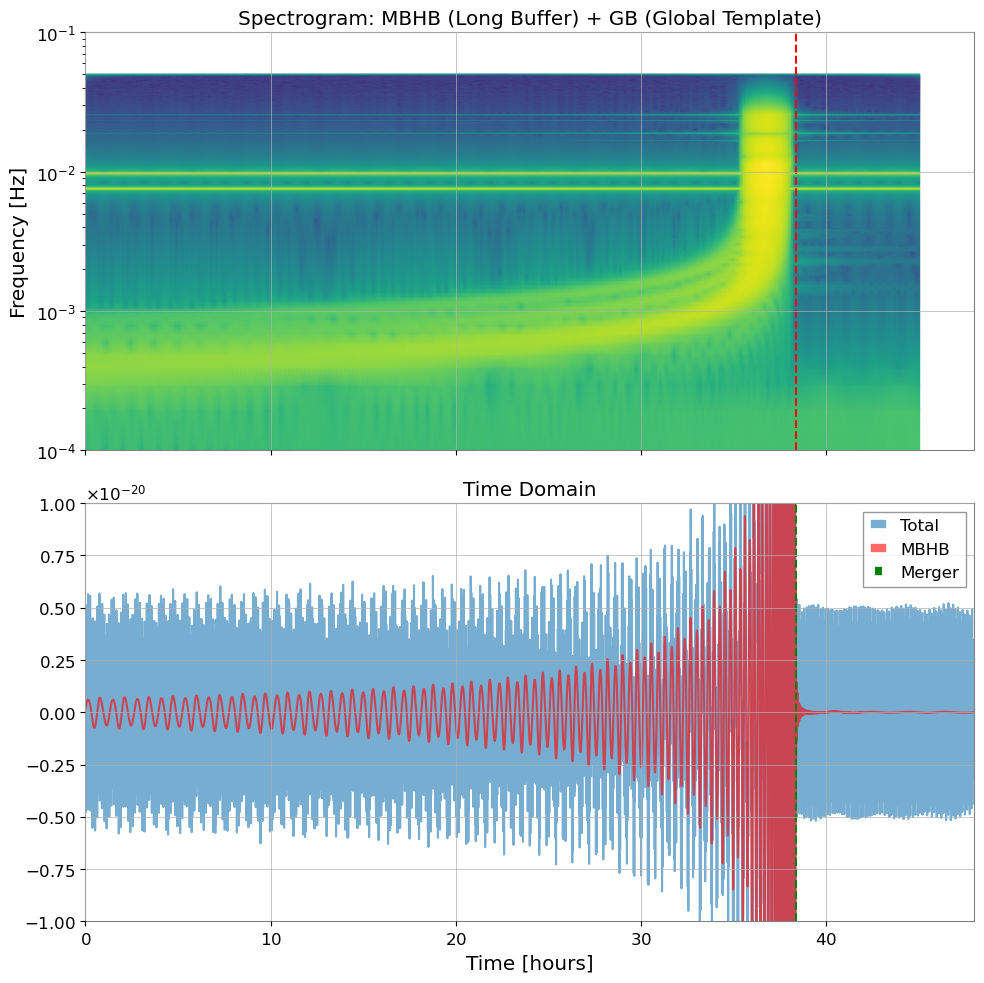

In [33]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
import torch
from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import PC_SI
from gbgpu.gbgpu import GBGPU



try:
    import cupy as cp
    xp = cp
    use_gpu = True
except ImportError:
    import numpy as xp
    use_gpu = False

import numpy as xp
use_gpu = False
dt = 10.0
fs = 1.0 / dt

T_obs = 48 * 3600            
N_obs = int(T_obs / dt)
N_freq_obs = N_obs // 2 + 1

T_gen = 30 * 24 * 3600       
N_gen = int(T_gen / dt)      

print(f"Observation Window: {T_obs/3600:.1f} hours")
print(f"Generation Buffer: {T_gen/86400:.1f} days")

wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))

m1, m2 = 6e5, 1e6
dist = 15e3 * PC_SI * 1e6
modes = [(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

t_merger_in_long_buffer = T_gen - (T_obs * 0.2) 
freqs_long = np.fft.rfftfreq(N_gen, dt)

wave_long_fd = wave_gen(
    m1, m2, 0.2, 0.4, dist,
    0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, 
    t_merger_in_long_buffer,
    t_obs_start=0.0, t_obs_end=T_gen, 
    freqs=freqs_long, modes=modes, direct=False, fill=True, length=N_gen
)[0]

h_long_td = np.fft.irfft(wave_long_fd, n=N_gen)
h_mbhb_cut = h_long_td[0, -N_obs:] 

n_binaries = 3
gb_params = np.zeros((9, n_binaries))

gb_params[0] = 10**np.random.uniform(-23, -21, n_binaries)
gb_params[1] = 10**np.random.uniform(np.log10(5e-3), np.log10(1e-2), n_binaries)
gb_params[2] = 10**np.random.uniform(-18, -16, n_binaries)
gb_params[3] = 0.0
gb_params[4] = np.random.uniform(0, 2*np.pi, n_binaries)
gb_params[5] = np.arccos(np.random.uniform(-1, 1, n_binaries))
gb_params[6] = np.random.uniform(0, np.pi, n_binaries)
gb_params[7] = np.random.uniform(0, 2*np.pi, n_binaries)
gb_params[8] = np.arcsin(np.random.uniform(-1, 1, n_binaries))

if use_gpu:
    gb_params_xp = cp.asarray(gb_params)
else:
    gb_params_xp = gb_params

gb = GBGPU(force_backend="cuda" if use_gpu else "cpu")

templates = xp.zeros((1, 2, N_freq_obs), dtype=xp.complex128)
group_index = xp.zeros(n_binaries, dtype=xp.int32)

gb.generate_global_template(
    gb_params_xp.T,
    group_index,
    templates,      
    T=T_obs, 
    dt=dt, 
    N=N_obs
)

A_channel_fd = templates[0, 0, :]

if use_gpu:
    h_gb_cut = cp.fft.irfft(A_channel_fd, n=N_obs).get()
else:
    h_gb_cut = np.fft.irfft(A_channel_fd, n=N_obs)

h_mix = h_mbhb_cut + h_gb_cut

fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

h_torch = torch.tensor(h_mix, dtype=torch.float32)

nperseg = 1024
noverlap = int(nperseg * 0.95)

Z_torch = torch.stft(
    h_torch,
    n_fft=nperseg,
    hop_length=nperseg - noverlap,
    window=torch.hann_window(nperseg),
    return_complex=True,
    center=False, 
    onesided=True
)
Z_mag = torch.abs(Z_torch).numpy()

t_axis = np.arange(Z_mag.shape[1]) * (nperseg - noverlap) * dt
f_axis = torch.fft.rfftfreq(nperseg, dt).numpy()

cut = 0

axes[0].pcolormesh(t_axis/3600, f_axis[cut:], np.log10(Z_mag[cut:,:] + 1e-30), 
                   shading='gouraud', cmap='viridis')
axes[0].set_title("Spectrogram: MBHB (Long Buffer) + GB (Global Template)")
axes[0].set_ylabel("Frequency [Hz]")
axes[0].axvline((T_obs * 0.8)/3600, color='r', linestyle='--', label='Merger')
axes[0].set_yscale('log')
axes[0].set_ylim(1e-4, 1e-1)

axes[1].plot(np.arange(N_obs)*dt/3600, h_mix, alpha=0.6, label='Total')
axes[1].plot(np.arange(N_obs)*dt/3600, h_mbhb_cut, color='r', alpha=0.6, label='MBHB')

axes[1].set_title("Time Domain")
axes[1].set_xlabel("Time [hours]")
axes[1].set_xlim(0, T_obs/3600)
axes[1].set_ylim(-1e-20, 1e-20)

axes[1].axvline((T_obs * 0.8)/3600, color='green', linestyle='--', label='Merger')
axes[1].legend()

plt.tight_layout()
plt.show()

## trying it on batched operations

In [1]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft, windows
import scipy.signal as signal

from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import YRSID_SI, PC_SI
from gbgpu.gbgpu import GBGPU
from gwpy.timeseries import TimeSeries

from kymatio.numpy import Scattering1D

dt = 10.0                       
fs = 1.0 / dt                   
Tobs = 2 * 24 * 3600            

N = 2**int(np.floor(np.log2(Tobs / dt)))
Tobs = N * dt                   
df = 1.0 / Tobs
t = np.arange(N) * dt
freqs_fft = np.fft.rfftfreq(N, dt)

print(f"Observation: {Tobs/3600:.1f} hours")
print(f"Points (N): {N}")
print(f"Nyquist Freq: {fs/2:.2f} Hz")

LOG: [fix_cupy] Attempting to patch CuPy...
LOG: [fix_cupy] Patching cupy.cuda.runtime._getLocalRuntimeVersion
LOG: [fix_cupy] Patch complete.
Observation: 45.5 hours
Points (N): 16384
Nyquist Freq: 0.05 Hz


In [2]:
wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))

n_samples = 10
n_batches = 2

n_samples = 10

m1 = torch.empty(n_samples).uniform_(1e5, 1e7).numpy()
m2 = torch.empty(n_samples).uniform_(1e5, 1e7).numpy()
t_ref = (Tobs * torch.empty(n_samples).uniform_(0.4, 0.9)).numpy()
dist = torch.empty(n_samples).uniform_(9e3 * PC_SI * 1e6, 18e3 * PC_SI * 1e6).numpy()

chi1 = np.full(n_samples, 0.2)
chi2 = np.full(n_samples, 0.4)
phi_ref = np.zeros(n_samples)
f_ref = np.zeros(n_samples)
inc = np.full(n_samples, np.pi/3)
lam = np.full(n_samples, np.pi/5)
beta = np.full(n_samples, np.pi/4)
psi = np.full(n_samples, np.pi/6)

modes = [(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

wave_mbhb = wave_gen(
    m1, m2, chi1, chi2, dist,
    phi_ref, f_ref, inc, lam, beta, psi, t_ref,
    t_obs_start=0.0, t_obs_end=Tobs, 
    freqs=freqs_fft, modes=modes, direct=False, fill=True, length=N
)[0]

h_mbhb_td = torch.fft.irfft(torch.tensor(wave_mbhb), n=N, dim=-1)


######################################
gb = GBGPU(force_backend="cpu")


n_gb_per_mbhb = 3
n_gb_tot = n_gb_per_mbhb * n_samples

amp_tensor = torch.Tensor

amp = np.array([3e-22, 2e-22, 8e-22])
f0 = np.array([2.0e-3, 5.5e-3, 3.0e-3])
fdot = np.array([1e-17, 1e-17, 1e-17])
zeros = np.zeros(3)
params = np.array([amp, f0, fdot, zeros, zeros, zeros+0.5, zeros, zeros, zeros])

gb.run_wave(*params, N=N, dt=dt, T=Tobs, oversample=2)
A_gb_fd = gb.A 

h_gb_fd = np.zeros_like(freqs_fft, dtype=complex)
for i in range(3):
    h_gb_fd += np.interp(freqs_fft, gb.freqs[i], A_gb_fd[i].real) + \
               1j * np.interp(freqs_fft, gb.freqs[i], A_gb_fd[i].imag)

h_gb_td = np.fft.irfft(h_gb_fd, n=N)

np.random.seed(42)
noise_amp = 1e-21 
noise = np.random.normal(0, noise_amp, N)

h_mix = h_mbhb_td + h_gb_td + noise

print("Data Generation Complete.")

NameError: name 'torch' is not defined

# -----------------------
# ----------------------



# Test scattering representation

In [8]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft, windows
import scipy.signal as signal

from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import YRSID_SI, PC_SI
from gbgpu.gbgpu import GBGPU
from gwpy.timeseries import TimeSeries

from kymatio.numpy import Scattering1D

dt = 10.0                       
fs = 1.0 / dt                   
Tobs = 2 * 24 * 3600            

N = 2**int(np.floor(np.log2(Tobs / dt)))
Tobs = N * dt                   
df = 1.0 / Tobs
t = np.arange(N) * dt
freqs_fft = np.fft.rfftfreq(N, dt)

print(f"Observation: {Tobs/3600:.1f} hours")
print(f"Points (N): {N}")
print(f"Nyquist Freq: {fs/2:.2f} Hz")

Observation: 45.5 hours
Points (N): 16384
Nyquist Freq: 0.05 Hz


In [12]:
wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))

m1, m2 = 6e5, 1e6
t_ref = Tobs * 0.8  
dist = 15e3 * PC_SI * 1e6
modes = [(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

wave_mbhb = wave_gen(
    m1, m2, 0.2, 0.4, dist,
    0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, t_ref,
    t_obs_start=0.0, t_obs_end=Tobs, 
    freqs=freqs_fft, modes=modes, direct=False, fill=True, length=N
)[0]

h_mbhb_td = np.fft.irfft(wave_mbhb[0], n=N)

gb = GBGPU(force_backend="cpu")

amp = np.array([3e-22, 2e-22, 8e-22])
f0 = np.array([2.0e-3, 5.5e-3, 3.0e-3])
fdot = np.array([1e-17, 1e-17, 1e-17])
zeros = np.zeros(3)
params = np.array([amp, f0, fdot, zeros, zeros, zeros+0.5, zeros, zeros, zeros])

gb.run_wave(*params, N=N, dt=dt, T=Tobs, oversample=2)
A_gb_fd = gb.A 

h_gb_fd = np.zeros_like(freqs_fft, dtype=complex)
for i in range(3):
    h_gb_fd += np.interp(freqs_fft, gb.freqs[i], A_gb_fd[i].real) + \
               1j * np.interp(freqs_fft, gb.freqs[i], A_gb_fd[i].imag)

h_gb_td = np.fft.irfft(h_gb_fd, n=N)

np.random.seed(42)
noise_amp = 1e-21 
noise = np.random.normal(0, noise_amp, N)

h_mix = h_mbhb_td + h_gb_td + 0*noise

print("Data Generation Complete.")

Data Generation Complete.


16384 (179, 16384)


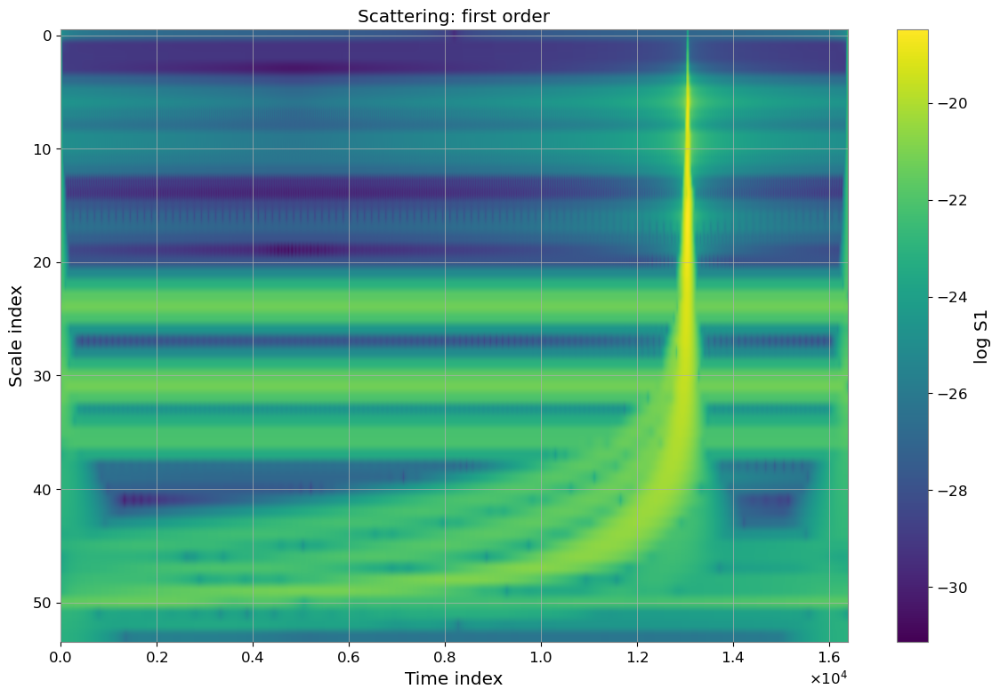

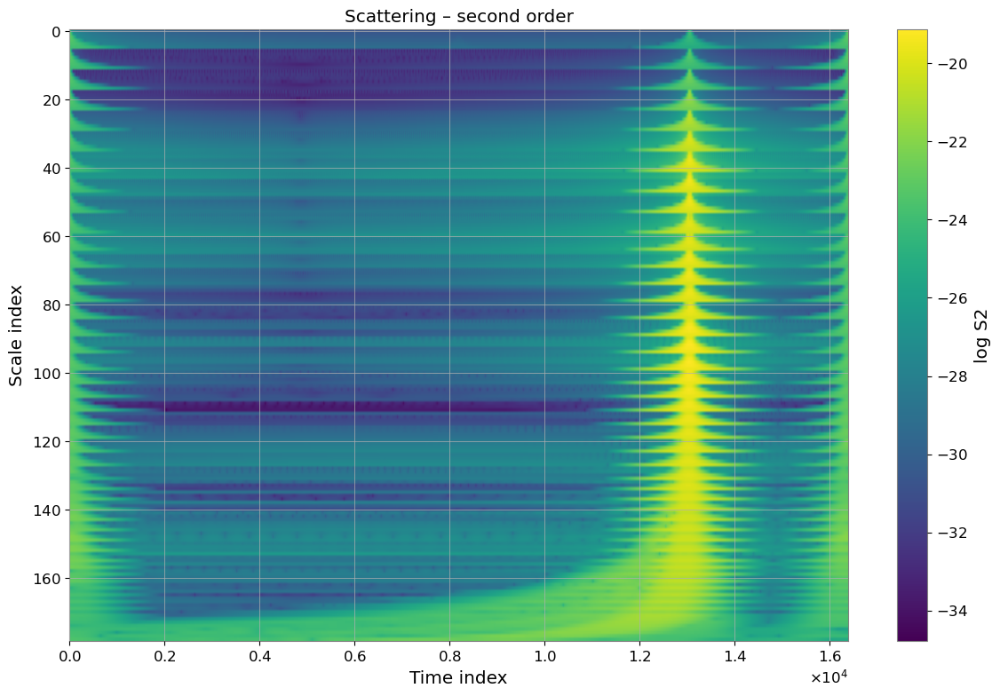

In [13]:
from kymatio.numpy import Scattering1D
import numpy as np
import matplotlib.pyplot as plt

J = 8      
Q = 8     
T = 1 

scat = Scattering1D(
    J=J,
    shape=h_mix.size,
    Q=Q,
    T=T,
    max_order=2
)

S = scat(h_mix)
meta = scat.meta()


order = meta['order']
S0 = S[order == 0]
S1 = S[order == 1]
S2 = S[order == 2]

print(len(h_mix), S2.shape)

plt.figure(figsize=(12,8))
plt.imshow(
	np.log10(S1),
	aspect='auto',
	origin='lower',
	cmap='viridis'
)
plt.gca().invert_yaxis()
plt.colorbar(label='log S1')

plt.xlabel('Time index')
plt.ylabel('Scale index')
plt.title('Scattering: first order')
plt.tight_layout()

plt.figure(figsize=(12,8))
plt.imshow(
	np.log10(S2 ),
	aspect='auto',
	origin='lower',
	cmap='viridis'
)
plt.gca().invert_yaxis()
plt.colorbar(label='log S2')

plt.xlabel('Time index')
plt.ylabel('Scale index')
plt.title('Scattering – second order')
plt.tight_layout()




## problem: wrap around!

I need to produce the signal on a bigger window ( longer than the signal !!) and then cut it to only the part i am interested in !!!!




Wanted Observation: 48.0 hours
Generation Buffer : 30.0 days (Safe Zone)
Cut MBHB shape: (17280,)
17280 (179, 17280)


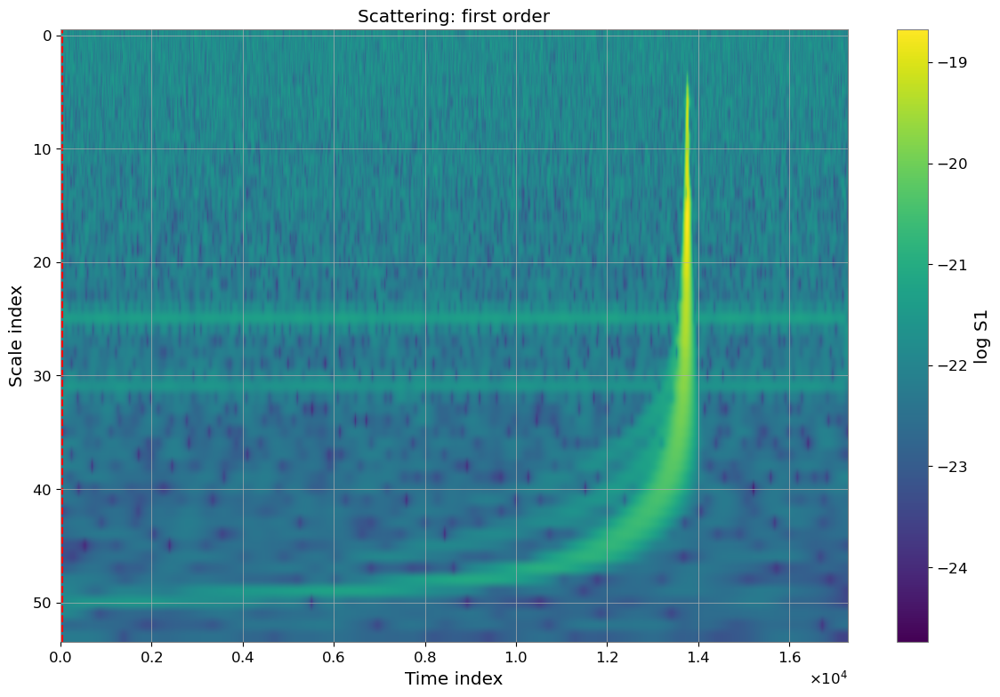

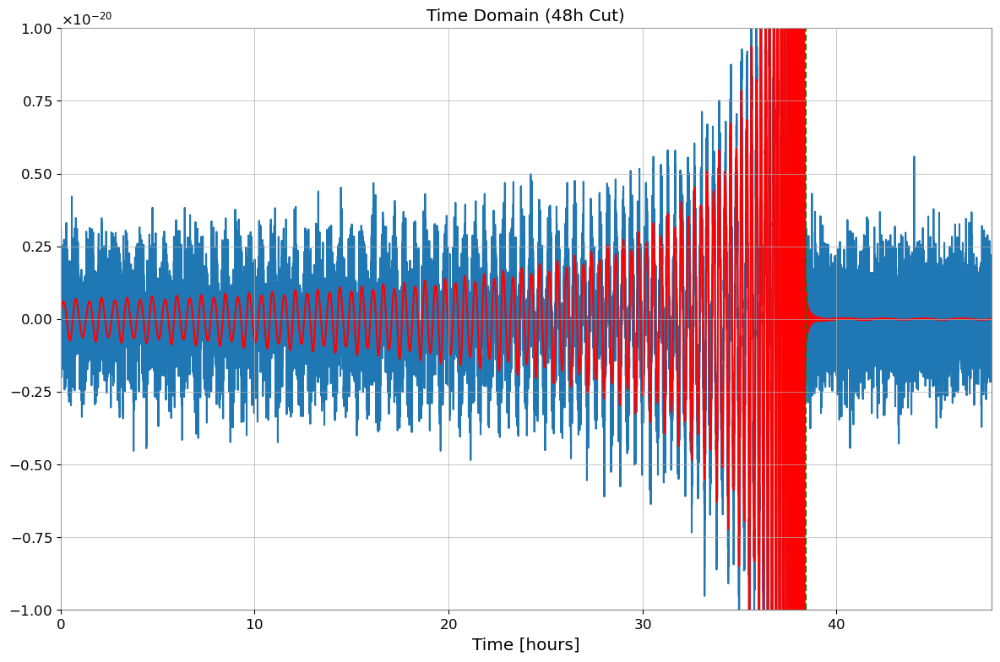

In [ ]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
import torch
from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import PC_SI
from gbgpu.gbgpu import GBGPU

dt = 10.0
fs = 1.0 / dt
T_obs = 48 * 3600            
N_obs = int(T_obs / dt)

T_gen = 30 * 24 * 3600       
N_gen = int(T_gen / dt)      

print(f"Wanted Observation: {T_obs/3600:.1f} hours")
print(f"Generation Buffer : {T_gen/86400:.1f} days (Safe Zone)")

wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))

m1, m2 = 6e5, 1e6
dist = 15e3 * PC_SI * 1e6
modes = [(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

t_merger_in_long_buffer = T_gen - (T_obs * 0.2) 

freqs_long = np.fft.rfftfreq(N_gen, dt)

wave_long_fd = wave_gen(
    m1, m2, 0.2, 0.4, dist,
    0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, 
    t_merger_in_long_buffer, 
    t_obs_start=0.0, t_obs_end=T_gen, 
    freqs=freqs_long, modes=modes, direct=False, fill=True, length=N_gen
)[0]

h_long_td = np.fft.irfft(wave_long_fd, n=N_gen)

h_mbhb_cut = h_long_td[0, -N_obs:] 

print(f"Cut MBHB shape: {h_mbhb_cut.shape}") 
gb = GBGPU(force_backend="cpu")
gb_params = np.array([
    [3e-22, 2e-22], [3.0e-3, 5.0e-3], [1e-17, 1e-17], 
    [0,0], [0,0], [0.5,0.5], [0,0], [0,0], [0,0]
])
gb.run_wave(*gb_params, N=N_obs, dt=dt, T=T_obs, oversample=2) 

h_gb_cut = np.zeros(N_obs)
freqs_short = np.fft.rfftfreq(N_obs, dt)

for i in range(len(gb_params[0])):
    
    gb_fd = np.interp(freqs_short, gb.freqs[i], gb.A[i].real) + \
            1j * np.interp(freqs_short, gb.freqs[i], gb.A[i].imag)
    h_gb_cut += np.fft.irfft(gb_fd, n=N_obs)


np.random.seed(42)
noise_amp = 1e-21 
noise = np.random.normal(0, noise_amp, N_obs)


h_mix = h_mbhb_cut + h_gb_cut + noise



from kymatio.numpy import Scattering1D
import numpy as np
import matplotlib.pyplot as plt

J = 8      
Q = 8     
T = 1 

scat = Scattering1D(
    J=J,
    shape=h_mix.size,
    Q=Q,
    T=T,
    max_order=2
)

S = scat(h_mix)
meta = scat.meta()


order = meta['order']
S0 = S[order == 0]
S1 = S[order == 1]
S2 = S[order == 2]

print(len(h_mix), S2.shape)

plt.figure(figsize=(12,8))
plt.imshow(
	np.log10(S1),
	aspect='auto',
	origin='lower',
	cmap='viridis'
)
plt.gca().invert_yaxis()
plt.colorbar(label='log S1')

plt.xlabel('Time index')
plt.ylabel('Scale index')
plt.title('Scattering: first order')
plt.axvline((T_obs * 0.8)/3600, color='r', linestyle='--', label='Merger')

plt.tight_layout()

plt.figure(figsize=(12,8))
plt.plot(np.arange(N_obs)*dt/3600, h_mix)
plt.plot(np.arange(N_obs)*dt/3600, h_mbhb_cut, color='r')

plt.title("Time Domain (48h Cut)")
plt.xlabel("Time [hours]")
plt.xlim(0, 48)
plt.axvline((T_obs * 0.8)/3600, color='green', linestyle='--', label='Merger')

plt.ylim(-1e-20, 1e-20)


plt.tight_layout()
plt.show()

### generating gbs.. no need for interpolation, can add them before

Using GPU (CuPy)
Running massive batch generation...
Done. Generated background from 100 binaries.
17280 (220, 17280)


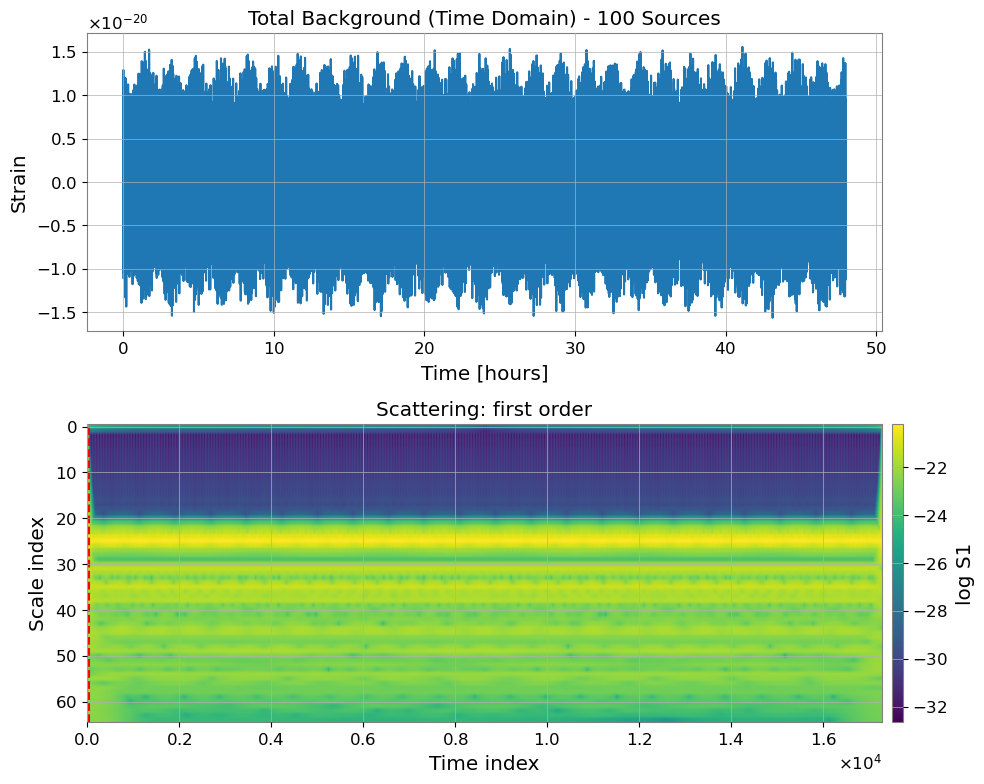

In [ ]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
from gbgpu.gbgpu import GBGPU
import torch

try:
    import cupy as cp
    xp = cp
    use_gpu = True
    print("Using GPU (CuPy)")
except ImportError:
    import numpy as xp
    use_gpu = False
    print("Using CPU (NumPy)")
import numpy as xp
use_gpu = False
dt = 10.0
T_obs = 48 * 3600            
N_obs = int(T_obs / dt)
N_freq = N_obs // 2 + 1 

n_binaries = 100  

gb_params = np.zeros((9, n_binaries))

gb_params[0] = 10**np.random.uniform(-23, -21, n_binaries) 
gb_params[1] = 10**np.random.uniform(np.log10(1e-4), np.log10(1e-2), n_binaries)   
gb_params[2] = 10**np.random.uniform(-18, -16, n_binaries)
gb_params[3] = 0.0
gb_params[4] = np.random.uniform(0, 2*np.pi, n_binaries)
gb_params[5] = np.arccos(np.random.uniform(-1, 1, n_binaries))
gb_params[6] = np.random.uniform(0, np.pi, n_binaries)
gb_params[7] = np.random.uniform(0, 2*np.pi, n_binaries)
gb_params[8] = np.arcsin(np.random.uniform(-1, 1, n_binaries))

if use_gpu:
    gb_params_xp = cp.asarray(gb_params)
else:
    gb_params_xp = gb_params

gb = GBGPU(force_backend="cuda" if use_gpu else "cpu")

templates = xp.zeros((1, 2, N_freq), dtype=xp.complex128)

group_index = xp.zeros(n_binaries, dtype=xp.int32)

print("Running massive batch generation...")
gb.generate_global_template(
    gb_params_xp.T, 
    group_index,
    templates,      
    T=T_obs, 
    dt=dt, 
    N=N_obs 
)
A_channel_fd = templates[0, 0, :]

if use_gpu:
    h_gb_total = cp.fft.irfft(A_channel_fd, n=N_obs).get() 
else:
    h_gb_total = np.fft.irfft(A_channel_fd, n=N_obs)

print(f"Done. Generated background from {n_binaries} binaries.")


from kymatio.numpy import Scattering1D
import numpy as np
import matplotlib.pyplot as plt

J = 8      
Q = 10     
T = 1 

scat = Scattering1D(
    J=J,
    shape=h_gb_total.size,
    Q=Q,
    T=T,
    max_order=2
)

S = scat(h_gb_total)
meta = scat.meta()


order = meta['order']
S0 = S[order == 0]
S1 = S[order == 1]
S2 = S[order == 2]

print(len(h_gb_total), S2.shape)

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(np.arange(N_obs)*dt/3600, h_gb_total)
axes[0].set_title(f"Total Background (Time Domain) - {n_binaries} Sources")
axes[0].set_xlabel("Time [hours]")
axes[0].set_ylabel("Strain")

axes[1].imshow(
	np.log10(S1),
	aspect='auto',
	origin='lower',
	cmap='viridis'
)
axes[1].invert_yaxis()
axes[1].colorbar(label='log S1')

axes[1].set_xlabel('Time index')
axes[1].set_ylabel('Scale index')
axes[1].set_title('Scattering: first order')
axes[1].axvline((T_obs * 0.8)/3600, color='r', linestyle='--', label='Merger')

plt.tight_layout()


In [ ]:
import scripts.fix_cupy 
import numpy as np
import torch
import matplotlib.pyplot as plt

from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import YRSID_SI, PC_SI
from gbgpu.gbgpu import GBGPU

from kymatio.numpy import Scattering1D

dt = 10.0
fs = 1.0 / dt
Tobs_approx = 48 * 3600  

N = 2**int(np.floor(np.log2(Tobs_approx / dt)))
Tobs = N * dt

freqs_fft = np.fft.rfftfreq(N, dt)
N_freq = len(freqs_fft)

print(f"Observation: {Tobs/3600:.1f} hours")
print(f"Points (N): {N} | Freq Bins: {N_freq}")

print("Generating 10 MBHBs...")
wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))

n_samples = 10

m1 = torch.empty(n_samples).uniform_(1e5, 1e7).numpy()
m2 = torch.empty(n_samples).uniform_(1e5, 1e7).numpy()
t_ref = (Tobs * torch.empty(n_samples).uniform_(0.4, 0.9)).numpy()
dist = torch.empty(n_samples).uniform_(9e3 * PC_SI * 1e6, 18e3 * PC_SI * 1e6).numpy()

# Fill scalars into arrays
chi1 = np.full(n_samples, 0.2)
chi2 = np.full(n_samples, 0.4)
phi_ref = np.zeros(n_samples)
f_ref = np.zeros(n_samples)
inc = np.full(n_samples, np.pi/3)
lam = np.full(n_samples, np.pi/5)
beta = np.full(n_samples, np.pi/4)
psi = np.full(n_samples, np.pi/6)

modes = [(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

wave_mbhb_fd = wave_gen(
    m1, m2, chi1, chi2, dist,
    phi_ref, f_ref, inc, lam, beta, psi, t_ref,
    t_obs_start=0.0, t_obs_end=Tobs, 
    freqs=freqs_fft, modes=modes, direct=False, fill=True, length=N_freq
)[0]

h_mbhb_td = torch.fft.irfft(torch.tensor(wave_mbhb_fd), n=N, dim=-1).numpy()

print("Generating 100 Galactic Binaries background...")
gb = GBGPU(force_backend="cpu") 

n_binaries = 100
gb_params = np.zeros((9, n_binaries))

gb_params[0] = 10**np.random.uniform(-23, -21, n_binaries)                  # amp
gb_params[1] = 10**np.random.uniform(np.log10(1e-4), np.log10(1e-2), n_binaries) # f0
gb_params[2] = 10**np.random.uniform(-18, -16, n_binaries)                  # fdot
gb_params[3] = 0.0                                                          # fddot
gb_params[4] = np.random.uniform(0, 2*np.pi, n_binaries)                    # phi0
gb_params[5] = np.arccos(np.random.uniform(-1, 1, n_binaries))              # iota
gb_params[6] = np.random.uniform(0, np.pi, n_binaries)                      # psi
gb_params[7] = np.random.uniform(0, 2*np.pi, n_binaries)                    # lambda
gb_params[8] = np.arcsin(np.random.uniform(-1, 1, n_binaries))              # beta

templates = np.zeros((1, 2, N_freq), dtype=np.complex128)
group_index = np.zeros(n_binaries, dtype=np.int32)

gb.generate_global_template(
    gb_params.T, 
    group_index,
    templates,      
    T=Tobs, 
    dt=dt, 
    N=N 
)

A_channel_fd = templates[0, 0, :]
h_gb_td = np.fft.irfft(A_channel_fd, n=N)  

np.random.seed(42)
noise_amp = 1e-21 
noise = np.random.normal(0, noise_amp, N)  

h_mix = h_mbhb_td + h_gb_td + noise
print(f"Data Generation Complete. Mixed Shape: {h_mix.shape}")

print("Running Scattering Transform...")
scat = Scattering1D(
    J=8,
    shape=N,
    Q=6,
    T=1,
    max_order=2
)

S = scat(h_mix)
meta = scat.meta()

order = meta['order']
S1 = S[:, order == 1, :] 

sample_idx = 0
S1_0 = S1[sample_idx]
time_hours = np.arange(N) * dt / 3600

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(time_hours, h_mix[sample_idx])
axes[0].set_title(f"Mixed Signal {sample_idx} (1 MBHB + 100 GBs + Noise)")
axes[0].set_xlabel("Time [hours]")
axes[0].set_ylabel("Strain")

im = axes[1].imshow(
    np.log10(S1_0 + 1e-30), 
    aspect='auto',
    origin='lower',
    cmap='viridis',
    extent=[0, time_hours[-1], 0, S1_0.shape[0]] 
)
axes[1].invert_yaxis()
fig.colorbar(im, ax=axes[1], label='log10(S1)')

axes[1].set_xlabel('Time [hours]')
axes[1].set_ylabel('Scale index')
axes[1].set_title('Scattering: First Order')

plt.tight_layout()
plt.show()

LOG: [fix_cupy] Attempting to patch CuPy...
LOG: [fix_cupy] Patching cupy.cuda.runtime._getLocalRuntimeVersion
LOG: [fix_cupy] Patch complete.
Observation: 45.5 hours
Points (N): 16384 | Freq Bins: 8193
Generating 10 MBHBs...


## trying it on batched operations

In [1]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft, windows
import scipy.signal as signal
import torch

from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import YRSID_SI, PC_SI
from gbgpu.gbgpu import GBGPU
from gwpy.timeseries import TimeSeries

from kymatio.numpy import Scattering1D

dt = 10.0                       
fs = 1.0 / dt                   
Tobs = 2 * 24 * 3600            

N = 2**int(np.floor(np.log2(Tobs / dt)))
Tobs = N * dt                   
df = 1.0 / Tobs
t = np.arange(N) * dt
freqs_fft = np.fft.rfftfreq(N, dt)

print(f"Observation: {Tobs/3600:.1f} hours")
print(f"Points (N): {N}")
print(f"Nyquist Freq: {fs/2:.2f} Hz")

LOG: [fix_cupy] Attempting to patch CuPy...
LOG: [fix_cupy] Patching cupy.cuda.runtime._getLocalRuntimeVersion
LOG: [fix_cupy] Patch complete.
Observation: 45.5 hours
Points (N): 16384
Nyquist Freq: 0.05 Hz


In [ ]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft, windows
import scipy.signal as signal
import torch

from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import YRSID_SI, PC_SI
from gbgpu.gbgpu import GBGPU
from gwpy.timeseries import TimeSeries
from kymatio.numpy import Scattering1D

dt = 10.0                       
fs = 1.0 / dt                   
Tobs = 2 * 24 * 3600            

N = 2**int(np.floor(np.log2(Tobs / dt)))
Tobs = N * dt                   
df = 1.0 / Tobs
t = np.arange(N) * dt
freqs_fft = np.fft.rfftfreq(N, dt)
N_freq = len(freqs_fft)

print(f"Observation: {Tobs/3600:.1f} hours")
print(f"Points (N): {N}")
print(f"Nyquist Freq: {fs/2:.2f} Hz")

wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))

n_samples = 10

m1 = torch.empty(n_samples).uniform_(1e5, 1e7).numpy()
m2 = torch.empty(n_samples).uniform_(1e5, 1e7).numpy()
t_ref = (Tobs * torch.empty(n_samples).uniform_(0.4, 0.9)).numpy()
dist = torch.empty(n_samples).uniform_(9e3 * PC_SI * 1e6, 18e3 * PC_SI * 1e6).numpy()

chi1 = np.full(n_samples, 0.2)
chi2 = np.full(n_samples, 0.4)
phi_ref = np.zeros(n_samples)
f_ref = np.zeros(n_samples)
inc = np.full(n_samples, np.pi/3)
lam = np.full(n_samples, np.pi/5)
beta = np.full(n_samples, np.pi/4)
psi = np.full(n_samples, np.pi/6)

modes = [(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

wave_mbhb = wave_gen(
    m1, m2, chi1, chi2, dist,
    phi_ref, f_ref, inc, lam, beta, psi, t_ref,
    t_obs_start=0.0, t_obs_end=Tobs, 
    freqs=freqs_fft, modes=modes, direct=False, fill=True, length=N
)[0]

h_mbhb_td = torch.fft.irfft(torch.tensor(wave_mbhb), n=N, dim=-1)

gb = GBGPU(force_backend="cpu")

n_gb_per_mbhb = 3
n_gb_tot = n_gb_per_mbhb * n_samples 

params = np.zeros((n_gb_tot, 9), dtype=np.float64)

params[:, 0] = 10**np.random.uniform(-23, -21, n_gb_tot)                 # amp
params[:, 1] = 10**np.random.uniform(np.log10(1e-4), np.log10(1e-2), n_gb_tot) # f0
params[:, 2] = 10**np.random.uniform(-18, -16, n_gb_tot)                 # fdot
params[:, 3] = 0.0                                                       # fddot
params[:, 4] = np.random.uniform(0, 2*np.pi, n_gb_tot)                   # phi0
params[:, 5] = np.arccos(np.random.uniform(-1, 1, n_gb_tot))             # iota
params[:, 6] = np.random.uniform(0, np.pi, n_gb_tot)                     # psi
params[:, 7] = np.random.uniform(0, 2*np.pi, n_gb_tot)                   # lambda
params[:, 8] = np.arcsin(np.random.uniform(-1, 1, n_gb_tot))             # beta

group_index = np.repeat(np.arange(n_samples, dtype=np.int32), n_gb_per_mbhb)
templates = np.zeros((n_samples, 2, N_freq), dtype=np.complex128)

gb.generate_global_template(
    params, 
    group_index, 
    templates,      
    T=Tobs, 
    dt=dt, 
    N=N 
)

A_gb_fd = templates[:, 0, :]

h_gb_td = np.fft.irfft(A_gb_fd, n=N, axis=-1)

np.random.seed(42)
noise_amp = 1e-21 
noise = np.random.normal(0, noise_amp, (n_samples, N))
h_mix = h_mbhb_td.numpy() + h_gb_td + noise

print(f"Data Generation Complete. Final shape is {h_mix.shape}")

# -----------------------
# ----------------------



# Test superlet representation

In [1]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft, windows
import scipy.signal as signal

from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import YRSID_SI, PC_SI
from gbgpu.gbgpu import GBGPU
from gwpy.timeseries import TimeSeries

from kymatio.numpy import Scattering1D

dt = 10.0                       
fs = 1.0 / dt                   
Tobs = 2 * 24 * 3600   
df= 1/Tobs

N = 2**int(np.floor(np.log2(Tobs / dt)))
t = np.arange(N) * dt
freqs_fft = np.fft.rfftfreq(N, dt)

print(f"Observation: {Tobs/3600:.1f} hours")
print(f"Points (N): {N}")
print(f"Nyquist Freq: {fs/2:.2f} Hz")

LOG: [fix_cupy] Attempting to patch CuPy...


/sps/lisaf/mbellotti/anaconda3/envs/bbhx_gbgpu_backup/lib/python3.12/site-packages/cupyx/scipy/sparse/_base.py:10: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.4.2)
  import scipy.sparse as _sparse


LOG: [fix_cupy] Patching cupy.cuda.runtime._getLocalRuntimeVersion
LOG: [fix_cupy] Patch complete.
Observation: 48.0 hours
Points (N): 16384
Nyquist Freq: 0.05 Hz


In [ ]:
# MBHB

wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))

m1, m2 = 6e5, 1e6
t_ref = Tobs * 0.8  
dist = 15e3 * PC_SI * 1e6
modes = [(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

wave_mbhb = wave_gen(
    m1, m2, 0.2, 0.4, dist,
    0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, t_ref,
    t_obs_start=0.0, t_obs_end=Tobs, 
    freqs=freqs_fft, modes=modes, direct=False, fill=True, length=N
)[0]

h_mbhb_td = np.fft.irfft(wave_mbhb[0], n=N)


# GBS 

gb = GBGPU(force_backend="cpu")

amp = np.array([3e-22, 2e-22, 8e-22])
f0 = np.array([2.0e-3, 5.5e-3, 3.0e-3])
fdot = np.array([1e-17, 1e-17, 1e-17])
zeros = np.zeros(3)
params = np.array([amp, f0, fdot, zeros, zeros, zeros+0.5, zeros, zeros, zeros])

gb.run_wave(*params, N=N, dt=dt, T=Tobs, oversample=2)
A_gb_fd = gb.A 

h_gb_fd = np.zeros_like(freqs_fft, dtype=complex)
for i in range(3):
    h_gb_fd += np.interp(freqs_fft, gb.freqs[i], A_gb_fd[i].real) + \
               1j * np.interp(freqs_fft, gb.freqs[i], A_gb_fd[i].imag)

h_gb_td = np.fft.irfft(h_gb_fd, n=N)

from lisatools.sensitivity import get_sensitivity

psd_A = np.zeros_like(freqs_fft)
valid_mask = freqs_fft >= 1e-9
psd_A[valid_mask] = get_sensitivity(freqs_fft[valid_mask], sens_fn="A1TDISens")

sigma_fd = np.zeros_like(psd_A)
sigma_fd[valid_mask] = np.sqrt(psd_A[valid_mask] / (4 * df))

noise_real = np.random.normal(0, sigma_fd)
noise_imag = np.random.normal(0, sigma_fd)

noise_real[0] = 0.0
noise_imag[0] = 0.0

if N % 2 == 0:
    noise_imag[-1] = 0.0
    if valid_mask[-1]: 
        noise_real[-1] = np.random.normal(0, np.sqrt(N / (2 * dt) * psd_A[-1]))
    else:
        noise_real[-1] = 0.0

noise_fd = noise_real + 1j * noise_imag

noise_td = np.fft.irfft(noise_fd, n=N)

h_mix = h_mbhb_td + h_gb_td + noise_td

print("Data Generation Complete.")


Data Generation Complete.


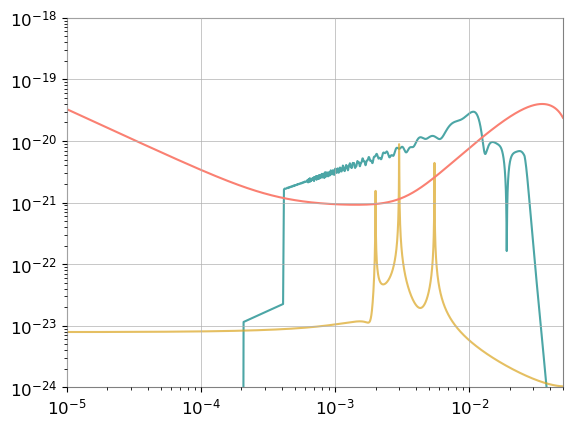

(-1e-19, 1e-19)

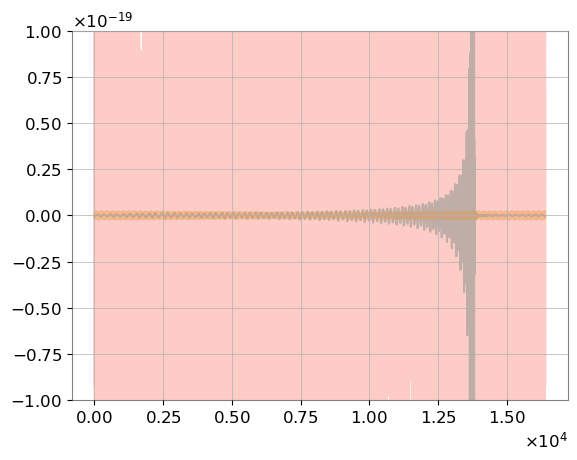

In [3]:
plt.loglog(freqs_fft, np.abs(np.fft.rfft(h_mbhb_td))* (2 * dt / N), color='teal', alpha=0.7, label="MBHB")
plt.loglog(freqs_fft, np.abs(np.fft.rfft(h_gb_td))* (2 * dt / N), color='goldenrod', alpha=0.7, label="Galactic Binaries")
plt.loglog(freqs_fft, np.sqrt(psd_A), color='salmon')
plt.ylim(1e-24, 1e-18)
plt.xlim(1e-5,np.max(freqs_fft))
plt.show()

#times = n
plt.plot(h_mbhb_td, alpha = 0.4, color= 'teal')
plt.plot(h_gb_td,  alpha = 0.4, color='goldenrod')
plt.plot(noise_td,  alpha = 0.4, color = 'salmon')
plt.ylim(-1e-19, 1e-19)


In [ ]:

from scripts.superlet import superlets, adaptive_superlet_transform
import jax.numpy as jnp

mask = (freqs_fft > 1e-4) & (freqs_fft <= 2e-2)
freqs_clean = freqs_fft[mask]

print(f"Running superlets on {len(freqs_clean)} frequency bins...")

result_np = superlets(
    data=h_mix, 
    fs=fs, 
    foi=freqs_clean, 
    c1=3, 
    ord=(1, 10)
)
print("NumPy Superlet shape:", result_np.shape)
'''
# --- JAX VERSION ---
h_mix_jax = jnp.array(h_mix)
freqs_jax = jnp.array(freqs_clean)

result_jax = adaptive_superlet_transform(
    signal=h_mix_jax,
    freqs=freqs_jax,
    sampling_freq=fs,  # fs is 0.1
    base_cycle=3,
    min_order=1,
    max_order=10
)
print("JAX Superlet shape:", result_jax.shape)'''

Running superlets on 3260 frequency bins...
NumPy Superlet shape: (3260, 16384)


'\n# --- JAX VERSION ---\nh_mix_jax = jnp.array(h_mix)\nfreqs_jax = jnp.array(freqs_clean)\n\nresult_jax = adaptive_superlet_transform(\n    signal=h_mix_jax,\n    freqs=freqs_jax,\n    sampling_freq=fs,  # fs is 0.1\n    base_cycle=3,\n    min_order=1,\n    max_order=10\n)\nprint("JAX Superlet shape:", result_jax.shape)'

In [ ]:
h_mix_jax = jnp.array(h_mix)
freqs_jax = jnp.array(freqs_clean)

result_jax = adaptive_superlet_transform(
    signal=h_mix_jax,
    freqs=freqs_jax,
    sampling_freq=fs, 
    base_cycle=3,
    min_order=1,
    max_order=10
)
print("JAX Superlet shape:", result_jax.shape)

Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/sps/lisaf/mbellotti/anaconda3/envs/bbhx_gbgpu_backup/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 497, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/sps/lisaf/mbellotti/anaconda3/envs/bbhx_gbgpu_backup/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 348, in initialize
    _check_cuda_versions(raise_on_first_error=True)
  File "/sps/lisaf/mbellotti/anaconda3/envs/bbhx_gbgpu_backup/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 274, in _check_cuda_versions
    for d in range(cuda_versions.cuda_device_count())
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:126: operation cuInit(0) failed: Unknown CUDA error 303; cuGetErrorName failed. This probably means that JAX was unable to load the CUDA libraries.


JAX Superlet shape: (3260, 16384)


/tmp/ipykernel_640/190464590.py:1: RuntimeWarning: divide by zero encountered in log10
  power = np.log10(result_np )


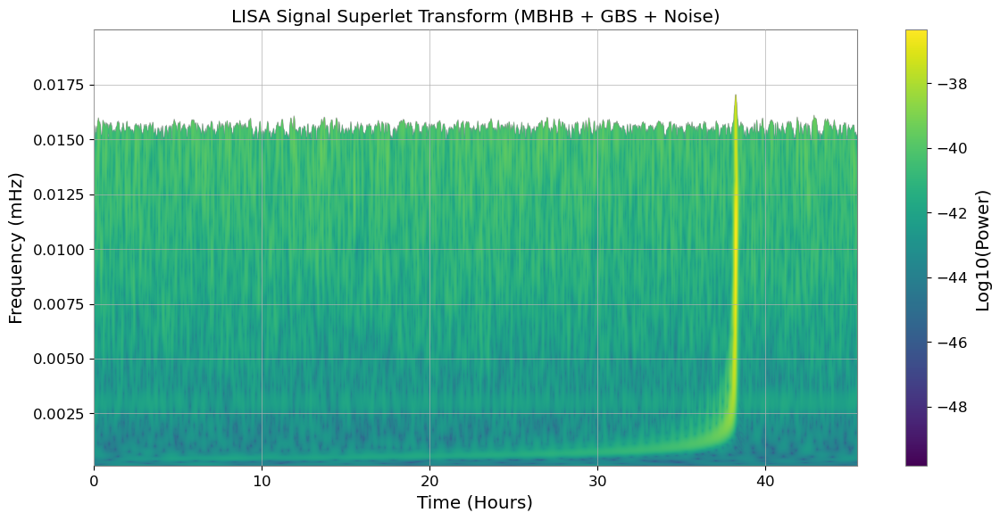

In [ ]:
power = np.log10(result_np )

plt.figure(figsize=(12, 6))

extent = [t[0]/3600, t[-1]/3600, freqs_clean[0], freqs_clean[-1]]

plt.imshow(power, aspect='auto', origin='lower', extent=extent, cmap='viridis')

plt.colorbar(label='Log10(Power)')
plt.xlabel('Time (Hours)')
plt.ylabel('Frequency (mHz)')
plt.title('LISA Signal Superlet Transform (MBHB + GBS + Noise)')

plt.tight_layout()
plt.show()

Computing Standard CWT: c1=3, ord=1 ...
Computing Standard CWT: c1=15, ord=1 ...
Computing Superlet: c1=8, ord=(1,5) ...
Computing Superlet: c1=10, ord=(1,20) ...


/tmp/ipykernel_640/1857065027.py:32: RuntimeWarning: divide by zero encountered in log10
  power = np.log10(result)


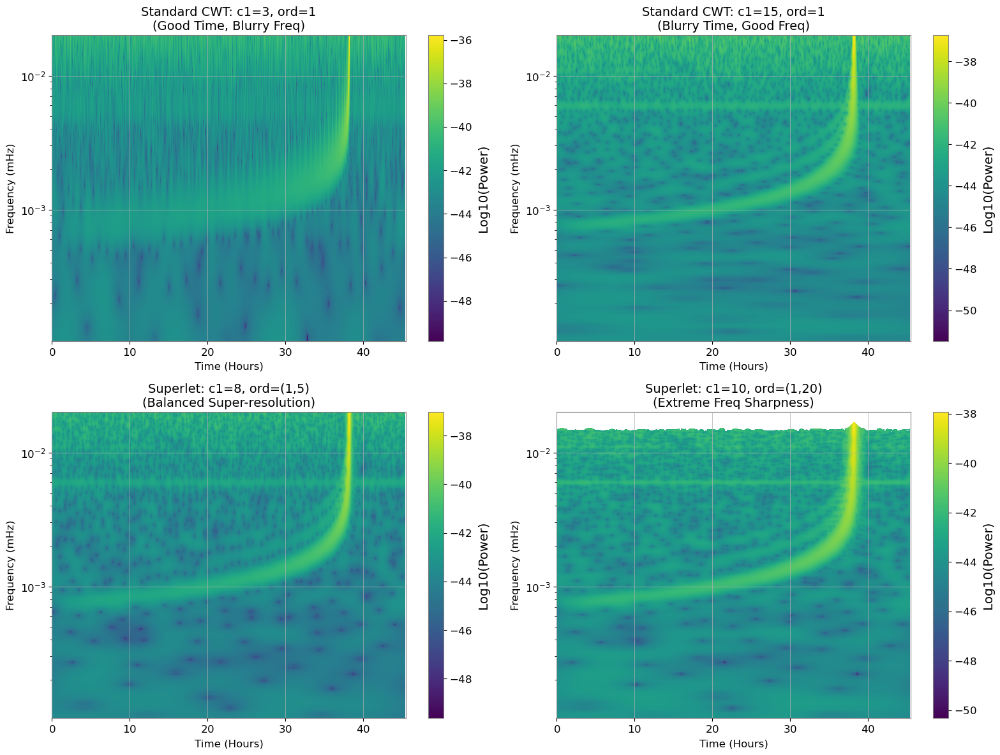

All done!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scripts.superlet import superlets

mask = (freqs_fft >= 1e-4) & (freqs_fft <= 10e-3)
freqs_clean = freqs_fft[mask]

configs =[
    (3,  (1, 1),  "Standard CWT: c1=3, ord=1\n(Good Time, Blurry Freq)"),
    (15, (1, 1),  "Standard CWT: c1=15, ord=1\n(Blurry Time, Good Freq)"),
    (8,  (1, 5),  "Superlet: c1=8, ord=(1,5)\n(Balanced Super-resolution)"),
    (10,  (1, 10), "Superlet: c1=10, ord=(1,20)\n(Extreme Freq Sharpness)")
]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (c1, ord_val, title) in enumerate(configs):
    print(f"Computing {title.split(chr(10))[0]} ...") 
    
    result = superlets(data=h_mix, fs=fs, foi=freqs_clean, c1=c1, ord=ord_val)
    
    power = np.log10(result)
    im = axes[i].imshow(power, aspect='auto', origin='lower', extent=extent, cmap='viridis')
    axes[i].set_title(title, fontsize=14)
    axes[i].set_xlabel('Time (Hours)', fontsize=12)
    axes[i].set_ylabel('Frequency (mHz)', fontsize=12)
    axes[i].set_yscale('log')
    fig.colorbar(im, ax=axes[i], label='Log10(Power)')

plt.tight_layout()
plt.show()
print("All done!")

### generating gbs.. no need for interpolation, can add them before

Using GPU (CuPy)
Running massive batch generation...
Done. Generated background from 100 binaries.
17280 (220, 17280)


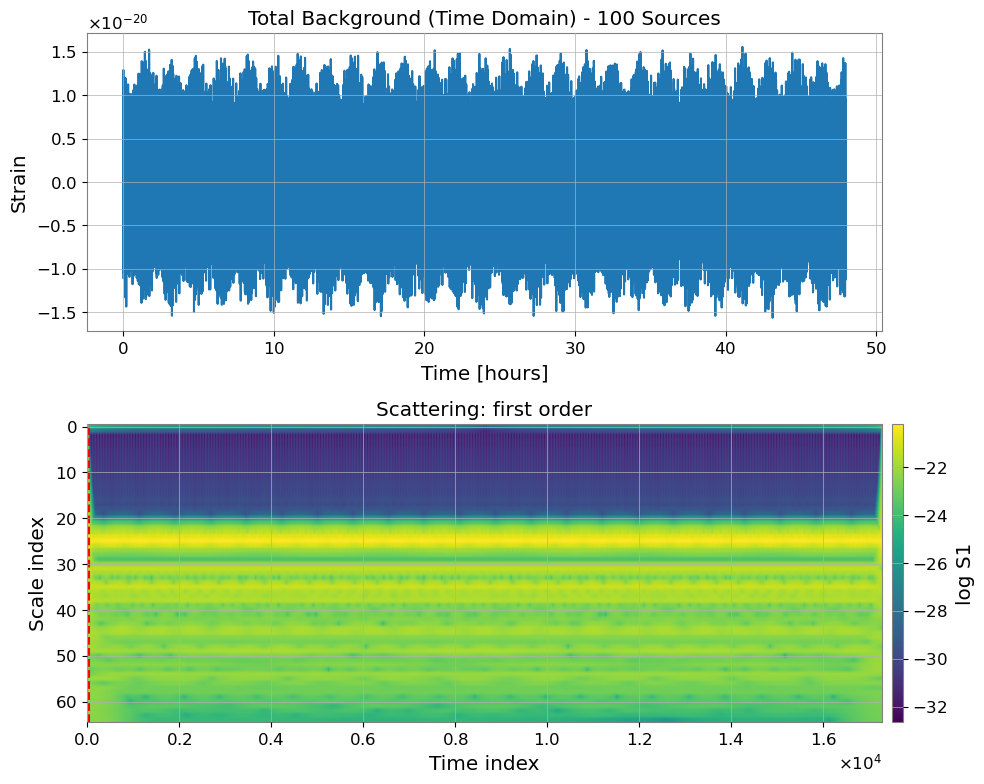

In [ ]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
from gbgpu.gbgpu import GBGPU
import torch

try:
    import cupy as cp
    xp = cp
    use_gpu = True
    print("Using GPU (CuPy)")
except ImportError:
    import numpy as xp
    use_gpu = False
    print("Using CPU (NumPy)")
import numpy as xp
use_gpu = False

dt = 10.0
T_obs = 48 * 3600            
N_obs = int(T_obs / dt)
N_freq = N_obs // 2 + 1 

n_binaries = 100  

gb_params = np.zeros((9, n_binaries))

# ampl
gb_params[0] = 10**np.random.uniform(-23, -21, n_binaries) 
# freq f0
gb_params[1] = 10**np.random.uniform(np.log10(1e-4), np.log10(1e-2), n_binaries)   
#  fdot 
gb_params[2] = 10**np.random.uniform(-18, -16, n_binaries)
# 3: fddot
gb_params[3] = 0.0
#  phi0
gb_params[4] = np.random.uniform(0, 2*np.pi, n_binaries)
# iota 
gb_params[5] = np.arccos(np.random.uniform(-1, 1, n_binaries))
#  psi
gb_params[6] = np.random.uniform(0, np.pi, n_binaries)
# lambda 
gb_params[7] = np.random.uniform(0, 2*np.pi, n_binaries)
# beta 
gb_params[8] = np.arcsin(np.random.uniform(-1, 1, n_binaries))

if use_gpu:
    gb_params_xp = cp.asarray(gb_params)
else:
    gb_params_xp = gb_params

gb = GBGPU(force_backend="cuda" if use_gpu else "cpu")

templates = xp.zeros((1, 2, N_freq), dtype=xp.complex128)

group_index = xp.zeros(n_binaries, dtype=xp.int32)

print("Running massive batch generation...")
gb.generate_global_template(
    gb_params_xp.T, 
    group_index,
    templates,      
    T=T_obs, 
    dt=dt, 
    N=N_obs 
)

A_channel_fd = templates[0, 0, :]

if use_gpu:
    h_gb_total = cp.fft.irfft(A_channel_fd, n=N_obs).get() 
else:
    h_gb_total = np.fft.irfft(A_channel_fd, n=N_obs)

print(f"Done. Generated background from {n_binaries} binaries.")


from kymatio.numpy import Scattering1D
import numpy as np
import matplotlib.pyplot as plt

J = 8      
Q = 10     
T = 1 

scat = Scattering1D(
    J=J,
    shape=h_gb_total.size,
    Q=Q,
    T=T,
    max_order=2
)

S = scat(h_gb_total)
meta = scat.meta()


order = meta['order']
S0 = S[order == 0]
S1 = S[order == 1]
S2 = S[order == 2]

print(len(h_gb_total), S2.shape)

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(np.arange(N_obs)*dt/3600, h_gb_total)
axes[0].set_title(f"Total Background (Time Domain) - {n_binaries} Sources")
axes[0].set_xlabel("Time [hours]")
axes[0].set_ylabel("Strain")

axes[1].imshow(
	np.log10(S1),
	aspect='auto',
	origin='lower',
	cmap='viridis'
)
axes[1].invert_yaxis()
axes[1].colorbar(label='log S1')

axes[1].set_xlabel('Time index')
axes[1].set_ylabel('Scale index')
axes[1].set_title('Scattering: first order')
axes[1].axvline((T_obs * 0.8)/3600, color='r', linestyle='--', label='Merger')

plt.tight_layout()


In [ ]:
import scripts.fix_cupy 
import numpy as np
import torch
import matplotlib.pyplot as plt

from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import YRSID_SI, PC_SI
from gbgpu.gbgpu import GBGPU

from kymatio.numpy import Scattering1D

dt = 10.0
fs = 1.0 / dt
Tobs_approx = 48 * 3600 

N = 2**int(np.floor(np.log2(Tobs_approx / dt)))
Tobs = N * dt

freqs_fft = np.fft.rfftfreq(N, dt)
N_freq = len(freqs_fft)

print(f"Observation: {Tobs/3600:.1f} hours")
print(f"Points (N): {N} | Freq Bins: {N_freq}")

print("Generating 10 MBHBs...")
wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))

n_samples = 10

m1 = torch.empty(n_samples).uniform_(1e5, 1e7).numpy()
m2 = torch.empty(n_samples).uniform_(1e5, 1e7).numpy()
t_ref = (Tobs * torch.empty(n_samples).uniform_(0.4, 0.9)).numpy()
dist = torch.empty(n_samples).uniform_(9e3 * PC_SI * 1e6, 18e3 * PC_SI * 1e6).numpy()

chi1 = np.full(n_samples, 0.2)
chi2 = np.full(n_samples, 0.4)
phi_ref = np.zeros(n_samples)
f_ref = np.zeros(n_samples)
inc = np.full(n_samples, np.pi/3)
lam = np.full(n_samples, np.pi/5)
beta = np.full(n_samples, np.pi/4)
psi = np.full(n_samples, np.pi/6)

modes = [(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

wave_mbhb_fd = wave_gen(
    m1, m2, chi1, chi2, dist,
    phi_ref, f_ref, inc, lam, beta, psi, t_ref,
    t_obs_start=0.0, t_obs_end=Tobs, 
    freqs=freqs_fft, modes=modes, direct=False, fill=True, length=N_freq
)[0]

h_mbhb_td = torch.fft.irfft(torch.tensor(wave_mbhb_fd), n=N, dim=-1).numpy()

gb = GBGPU(force_backend="cpu") 

n_binaries = 100
gb_params = np.zeros((9, n_binaries))

gb_params[0] = 10**np.random.uniform(-23, -21, n_binaries)                  # amp
gb_params[1] = 10**np.random.uniform(np.log10(1e-4), np.log10(1e-2), n_binaries) # f0
gb_params[2] = 10**np.random.uniform(-18, -16, n_binaries)                  # fdot
gb_params[3] = 0.0                                                          # fddot
gb_params[4] = np.random.uniform(0, 2*np.pi, n_binaries)                    # phi0
gb_params[5] = np.arccos(np.random.uniform(-1, 1, n_binaries))              # iota
gb_params[6] = np.random.uniform(0, np.pi, n_binaries)                      # psi
gb_params[7] = np.random.uniform(0, 2*np.pi, n_binaries)                    # lambda
gb_params[8] = np.arcsin(np.random.uniform(-1, 1, n_binaries))              # beta

templates = np.zeros((1, 2, N_freq), dtype=np.complex128)
group_index = np.zeros(n_binaries, dtype=np.int32)

gb.generate_global_template(
    gb_params.T, 
    group_index,
    templates,      
    T=Tobs, 
    dt=dt, 
    N=N 
)


A_channel_fd = templates[0, 0, :]
h_gb_td = np.fft.irfft(A_channel_fd, n=N)  
np.random.seed(42)
noise_amp = 1e-21 
noise = np.random.normal(0, noise_amp, N)  
h_mix = h_mbhb_td + h_gb_td + noise
scat = Scattering1D(
    J=8,
    shape=N,
    Q=10,
    T=1,
    max_order=2
)

S = scat(h_mix)
meta = scat.meta()

order = meta['order']
S1 = S[:, order == 1, :] 

sample_idx = 0
S1_0 = S1[sample_idx]
time_hours = np.arange(N) * dt / 3600

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(time_hours, h_mix[sample_idx])
axes[0].set_title(f"Mixed Signal {sample_idx} (1 MBHB + 100 GBs + Noise)")
axes[0].set_xlabel("Time [hours]")
axes[0].set_ylabel("Strain")

im = axes[1].imshow(
    np.log10(S1_0 + 1e-30), 
    aspect='auto',
    origin='lower',
    cmap='viridis',
    extent=[0, time_hours[-1], 0, S1_0.shape[0]] 
)
axes[1].invert_yaxis()
fig.colorbar(im, ax=axes[1], label='log10(S1)')

axes[1].set_xlabel('Time [hours]')
axes[1].set_ylabel('Scale index')
axes[1].set_title('Scattering: First Order')

plt.tight_layout()
plt.show()

LOG: [fix_cupy] Attempting to patch CuPy...
LOG: [fix_cupy] Patching cupy.cuda.runtime._getLocalRuntimeVersion
LOG: [fix_cupy] Patch complete.
Observation: 45.5 hours
Points (N): 16384 | Freq Bins: 8193
Generating 10 MBHBs...


## trying it on batched operations

In [ ]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft, windows
import scipy.signal as signal
import torch

from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import YRSID_SI, PC_SI
from gbgpu.gbgpu import GBGPU
from gwpy.timeseries import TimeSeries

from kymatio.numpy import Scattering1D

dt = 10.0                       
fs = 1.0 / dt                   
Tobs = 2 * 24 * 3600            

N = 2**int(np.floor(np.log2(Tobs / dt)))
Tobs = N * dt                   
df = 1.0 / Tobs
t = np.arange(N) * dt
freqs_fft = np.fft.rfftfreq(N, dt)

print(f"Observation: {Tobs/3600:.1f} hours")
print(f"Points (N): {N}")
print(f"Nyquist Freq: {fs/2:.2f} Hz")

LOG: [fix_cupy] Attempting to patch CuPy...
LOG: [fix_cupy] Patching cupy.cuda.runtime._getLocalRuntimeVersion
LOG: [fix_cupy] Patch complete.
Observation: 45.5 hours
Points (N): 16384
Nyquist Freq: 0.05 Hz


In [ ]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft, windows
import scipy.signal as signal
import torch

from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import YRSID_SI, PC_SI
from gbgpu.gbgpu import GBGPU
from gwpy.timeseries import TimeSeries
from kymatio.numpy import Scattering1D

dt = 10.0                       
fs = 1.0 / dt                   
Tobs = 2 * 24 * 3600            

N = 2**int(np.floor(np.log2(Tobs / dt)))
Tobs = N * dt                   
df = 1.0 / Tobs
t = np.arange(N) * dt
freqs_fft = np.fft.rfftfreq(N, dt)
N_freq = len(freqs_fft)

print(f"Observation: {Tobs/3600:.1f} hours")
print(f"Points (N): {N}")
print(f"Nyquist Freq: {fs/2:.2f} Hz")

wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))

n_samples = 10

m1 = torch.empty(n_samples).uniform_(1e5, 1e7).numpy()
m2 = torch.empty(n_samples).uniform_(1e5, 1e7).numpy()
t_ref = (Tobs * torch.empty(n_samples).uniform_(0.4, 0.9)).numpy()
dist = torch.empty(n_samples).uniform_(9e3 * PC_SI * 1e6, 18e3 * PC_SI * 1e6).numpy()

chi1 = np.full(n_samples, 0.2)
chi2 = np.full(n_samples, 0.4)
phi_ref = np.zeros(n_samples)
f_ref = np.zeros(n_samples)
inc = np.full(n_samples, np.pi/3)
lam = np.full(n_samples, np.pi/5)
beta = np.full(n_samples, np.pi/4)
psi = np.full(n_samples, np.pi/6)

modes = [(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

wave_mbhb = wave_gen(
    m1, m2, chi1, chi2, dist,
    phi_ref, f_ref, inc, lam, beta, psi, t_ref,
    t_obs_start=0.0, t_obs_end=Tobs, 
    freqs=freqs_fft, modes=modes, direct=False, fill=True, length=N
)[0]

h_mbhb_td = torch.fft.irfft(torch.tensor(wave_mbhb), n=N, dim=-1)

gb = GBGPU(force_backend="cpu")

n_gb_per_mbhb = 3
n_gb_tot = n_gb_per_mbhb * n_samples  
params = np.zeros((n_gb_tot, 9), dtype=np.float64)

params[:, 0] = 10**np.random.uniform(-23, -21, n_gb_tot)                 # amp
params[:, 1] = 10**np.random.uniform(np.log10(1e-4), np.log10(1e-2), n_gb_tot) # f0
params[:, 2] = 10**np.random.uniform(-18, -16, n_gb_tot)                 # fdot
params[:, 3] = 0.0                                                       # fddot
params[:, 4] = np.random.uniform(0, 2*np.pi, n_gb_tot)                   # phi0
params[:, 5] = np.arccos(np.random.uniform(-1, 1, n_gb_tot))             # iota
params[:, 6] = np.random.uniform(0, np.pi, n_gb_tot)                     # psi
params[:, 7] = np.random.uniform(0, 2*np.pi, n_gb_tot)                   # lambda
params[:, 8] = np.arcsin(np.random.uniform(-1, 1, n_gb_tot))             # beta

group_index = np.repeat(np.arange(n_samples, dtype=np.int32), n_gb_per_mbhb)

templates = np.zeros((n_samples, 2, N_freq), dtype=np.complex128)

gb.generate_global_template(
    params, 
    group_index, 
    templates,      
    T=Tobs, 
    dt=dt, 
    N=N 
)

A_gb_fd = templates[:, 0, :]

h_gb_td = np.fft.irfft(A_gb_fd, n=N, axis=-1)

np.random.seed(42)
noise_amp = 1e-21 
noise = np.random.normal(0, noise_amp, (n_samples, N))

h_mix = h_mbhb_td.numpy() + h_gb_td + noise



# SSQUEEZYPY 

In [1]:
import scripts.fix_cupy
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft, windows
import scipy.signal as signal

from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import YRSID_SI, PC_SI
from gbgpu.gbgpu import GBGPU
from gwpy.timeseries import TimeSeries

from kymatio.numpy import Scattering1D

dt = 10.0                       
fs = 1.0 / dt                   
Tobs = 2 * 24 * 3600   
df= 1/Tobs

N = 2**int(np.floor(np.log2(Tobs / dt)))
t = np.arange(N) * dt
freqs_fft = np.fft.rfftfreq(N, dt)

print(f"Observation: {Tobs/3600:.1f} hours")
print(f"Points (N): {N}")
print(f"Nyquist Freq: {fs/2:.2f} Hz")


LOG: [fix_cupy] Attempting to patch CuPy...


/sps/lisaf/mbellotti/anaconda3/envs/bbhx_gbgpu_backup/lib/python3.12/site-packages/cupyx/scipy/sparse/_base.py:10: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.3.5)
  import scipy.sparse as _sparse


LOG: [fix_cupy] Patching cupy.cuda.runtime._getLocalRuntimeVersion
LOG: [fix_cupy] Patch complete.
Observation: 48.0 hours
Points (N): 16384
Nyquist Freq: 0.05 Hz


In [ ]:
# MBHB

wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))

m1, m2 = 6e5, 1e6
t_ref = Tobs * 0.8  
dist = 15e3 * PC_SI * 1e6
modes = [(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

wave_mbhb = wave_gen(
    m1, m2, 0.2, 0.4, dist,
    0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, t_ref,
    t_obs_start=0.0, t_obs_end=Tobs, 
    freqs=freqs_fft, modes=modes, direct=False, fill=True, length=N
)[0]

h_mbhb_td = np.fft.irfft(wave_mbhb[0], n=N)


# GBS 

gb = GBGPU(force_backend="cpu")

amp = np.array([1e-21, 7e-22, 8e-22])
f0 = np.array([2.0e-3, 5.5e-3, 3.0e-3])
fdot = np.array([1e-17, 1e-17, 1e-17])
zeros = np.zeros(3)
params = np.array([amp, f0, fdot, zeros, zeros, zeros+0.5, zeros, zeros, zeros])

gb.run_wave(*params, N=N, dt=dt, T=Tobs, oversample=2)
A_gb_fd = gb.A 

h_gb_fd = np.zeros_like(freqs_fft, dtype=complex)
for i in range(3):
    h_gb_fd += np.interp(freqs_fft, gb.freqs[i], A_gb_fd[i].real) + \
               1j * np.interp(freqs_fft, gb.freqs[i], A_gb_fd[i].imag)

h_gb_td = np.fft.irfft(h_gb_fd, n=N)


# NOISE 
from lisatools.sensitivity import get_sensitivity

psd_A = np.zeros_like(freqs_fft)
valid_mask = freqs_fft >= 1e-9
psd_A[valid_mask] = get_sensitivity(freqs_fft[valid_mask], sens_fn="A1TDISens")

sigma_fd = np.zeros_like(psd_A)
sigma_fd[valid_mask] = np.sqrt(psd_A[valid_mask] / (4 * df))

noise_real = np.random.normal(0, sigma_fd)
noise_imag = np.random.normal(0, sigma_fd)

noise_real[0] = 0.0
noise_imag[0] = 0.0

if N % 2 == 0:
    noise_imag[-1] = 0.0
    if valid_mask[-1]: 
        noise_real[-1] = np.random.normal(0, np.sqrt(N / (2 * dt) * psd_A[-1]))
    else:
        noise_real[-1] = 0.0

noise_fd = noise_real + 1j * noise_imag

noise_td = np.fft.irfft(noise_fd, n=N)

h_mix = h_mbhb_td + h_gb_td + noise_td
#h_mix =  h_gb_td + noise_td

print("Data Generation Complete.")


Data Generation Complete.


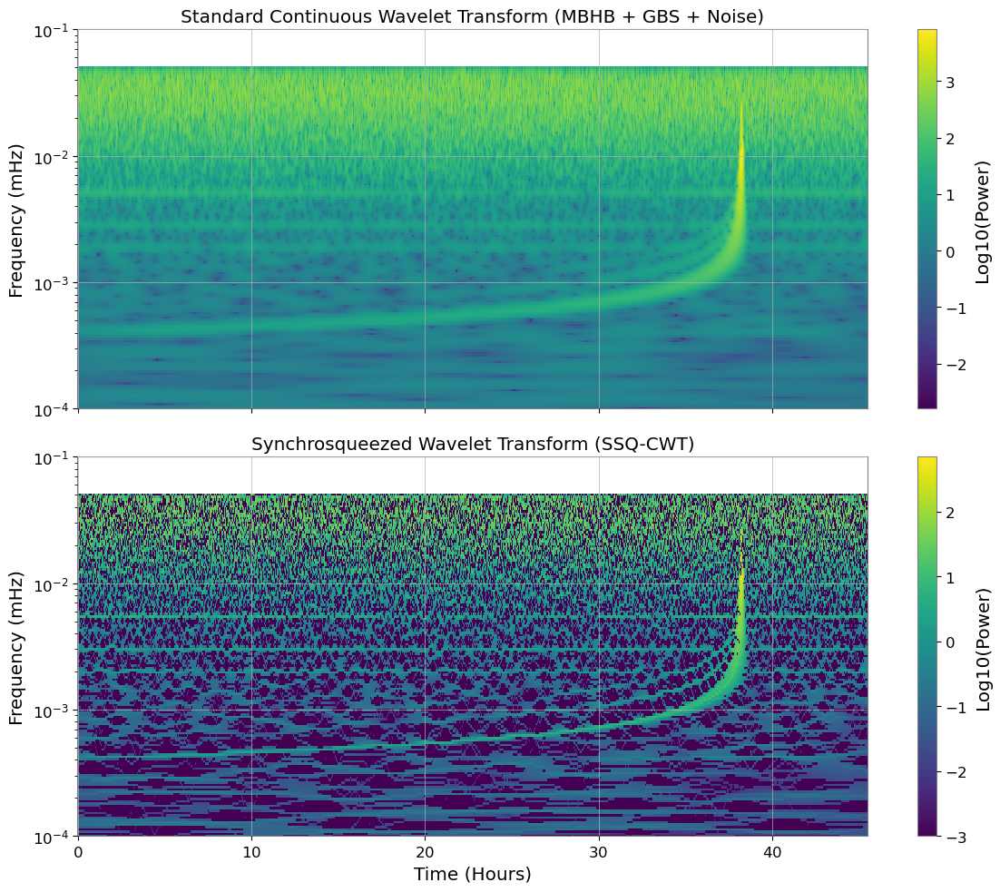

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from ssqueezepy import ssq_cwt

ssq_out = ssq_cwt(h_mix*1e22, fs=fs, wavelet='morlet', scales='log', nv=16, gamma=1e-10, padtype='zero')

Twx = ssq_out[0]
Wx = ssq_out[1]
ssq_freqs = ssq_out[2]

time_hours = t / 3600.0
freqs_mHz = ssq_freqs 

power_cwt = np.log10(np.abs(Wx) + 1e-3)
power_ssq = np.log10(np.abs(Twx)+ 1e-3)

fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

pcm0 = axes[0].pcolormesh(time_hours, freqs_mHz, power_cwt, cmap='viridis', shading='nearest')
axes[0].set_ylabel('Frequency (mHz)')
axes[0].set_title('Standard Continuous Wavelet Transform (MBHB + GBS + Noise)')
axes[0].set_ylim(1e-4, 1e-1)
axes[0].set_yscale('log')
fig.colorbar(pcm0, ax=axes[0], label='Log10(Power)')

pcm1 = axes[1].pcolormesh(time_hours, freqs_mHz, power_ssq, cmap='viridis', shading='nearest')
axes[1].set_xlabel('Time (Hours)')
axes[1].set_ylabel('Frequency (mHz)')
axes[1].set_title('Synchrosqueezed Wavelet Transform (SSQ-CWT)')
axes[1].set_ylim(1e-4, 1e-1)
axes[1].set_yscale('log')

fig.colorbar(pcm1, ax=axes[1], label='Log10(Power)')

plt.tight_layout()
plt.show()

def ssq_cwt(x, wavelet='gmw', scales='log-piecewise', nv=None, fs=None, t=None,
            ssq_freqs=None, padtype='reflect', squeezing='sum', maprange='peak',
            difftype='trig', difforder=None, gamma=None, vectorized=True,
            preserve_transform=None, astensor=True, order=0, nan_checks=None,
            patience=0, flipud=True, cache_wavelet=None,
            get_w=False, get_dWx=False):
    """Synchrosqueezed Continuous Wavelet Transform.
    Implements the algorithm described in Sec. III of [1].

    Uses `wavelet.dtype` precision.

    # Arguments:
        x: np.ndarray / torch.Tensor
            Input vector(s), 1D or 2D. See `help(cwt)`.

        wavelet: str / tuple[str, dict] / `wavelets.Wavelet`
            Wavelet sampled in Fourier frequency domain. See `help(cwt)`.

        scales: str['log', 'linear', 'log:maximal', ...] / np.ndarray
            CWT scales. See `help(cwt)`.

        nv: int / None
            Number of voices (wavelets per octave). Suggested >= 16.

        fs, t: float, np.ndarray
            See `help(_cwt.cwt)`.

        ssq_freqs: str['log', 'linear'] / np.ndarray / None
            Frequencies to synchrosqueeze CWT scales onto. Scale-frequency
            mapping is only approximate and wavelet-dependent.
            If None, will infer from and set to same distribution as `scales`.

        padtype: str / None
            Pad scheme to apply on input. See `help(utils.padsignal)`.
            `None` -> no padding.

        squeezing: str['sum', 'lebesgue'] / function
            See `help(ssqueezing.ssqueeze)`.

        maprange: str['maximal', 'peak', 'energy'] / tuple(float, float)
            Kind of frequency mapping used, determining the range of frequencies
            spanned (fm to fM, min to max).

                - 'maximal': fm=1/dT, fM=1/(2*dt), always. Data's fundamental
                and Nyquist frequencies, determined from `fs` (or `t`).
                Other mappings can never span outside this range.

                - ('peak', 'energy'): sets fm and fM based on center frequency
                associated with `wavelet` at maximum and minimum scale,
                respectively. See `help(wavelets.center_frequency)`.

                - 'peak': the frequency-domain trimmed bell will have its peak
                at Nyquist, meaning all other frequencies are beneath, so each
                scale is still correctly resolved but with downscaled energies.
                With sufficiently-spanned `scales`, coincides with 'maximal'.

                - 'energy': however, the bell's spectral energy is centered
                elsewhere, as right-half of bell is partly or entirely trimmed
                (left-half can be trimmed too). Use for energy-centric mapping,
                which for sufficiently-spanned `scales` will always have lesser
                fM (but ~same fM).

                - tuple: sets `ssq_freqrange` directly.

        difftype: str['trig', 'phase', 'numeric']
            Method by which to differentiate Wx (default='trig') to obtain
            instantaneous frequencies:
                    w(a,b) = Im( (1/2pi) * (1/Wx(a,b)) * d/db[Wx(a,b)] )

            - 'trig': use `dWx`, obtained via trigonometric (frequency-domain
            interpolant) differentiation (see `cwt`, `phase_cwt`).
            - 'phase': differentiate by taking forward finite-difference of
            unwrapped angle of `Wx` (see `phase_cwt`).
            - 'numeric': first-, second-, or fourth-order (set by `difforder`)
            numeric differentiation (see `phase_cwt_num`).

        difforder: int[1, 2, 4]
            Order of differentiation for difftype='numeric' (default=4).

        gamma: float / None
            CWT phase threshold. Sets `w=inf` for small values of `Wx` where
            phase computation is unstable and inaccurate (like in DFT):
                w[abs(Wx) < beta] = inf
            This is used to zero `Wx` where `w=0` in computing `Tx` to ignore
            contributions from points with indeterminate phase.
            Default = 10 * (machine epsilon) = 10 * np.finfo(np.float64).eps
            (or float32)

            It is recommended to standardize the input, or at least not
            pass a small-valued input, to avoid false filtering by `gamma`,
            especially if input obeys a power scaling law
            (e.g. `~1/f` with EEG/MEG, and similar with audio).
            # TODO warn user if `x.max()` is small?

        vectorized: bool (default True)
            Whether to vectorize CWT, i.e. compute quantities for all scales at
            once, which is faster but uses more memory.

        preserve_transform: bool (default None) / None
            Whether to return `Wx` as directly output from `cwt` (it might be
            altered by `ssqueeze` or `phase_transform`). Uses more memory
            per storing extra copy of `Wx`.
                - Defaults to True if `'SSQ_GPU' == '0'`, else False.

        astensor: bool (default True)
            If `'SSQ_GPU' == '1'`, whether to return arrays as on-GPU tensors
            or move them back to CPU & convert to Numpy arrays.

        order: int (default 0) / tuple[int]
            `order > 0` computes ssq of `cwt` taken with higher-order GMWs.
            If tuple, computes ssq of average of `cwt`s taken at each specified
            order. See `help(_cwt.cwt_higher_order)`.

        nan_checks: bool / None
            Checks whether input has `nan` or `inf` values, and zeros them.
            `False` saves compute. Doesn't support torch inputs.

            Defaults to `True` for NumPy inputs, else `False`.

        patience: int / tuple[int, int]
            pyFFTW parameter for faster FFT on CPU; see `help(ssqueezepy.FFT)`.

        flipud: bool (default True)
            See `help(ssqueeze)`.

        cache_wavelet: bool (default None) / None
            See `help(cwt)`.

        get_w, get_dWx: bool (default False)
            `get_w`:
                True: will compute phase transform separately, assign it to
                array `w` and return it.
                False: will compute synchrosqueezing directly from `Wx` and
                `dWx` without assigning to intermediate array, which is faster
                (by 20-30%) and takes less memory.
            `get_dWx`:
                True: will return dWx
                False: discards dWx after computing `w` or synchrosqueezing.
                `get_dWx=True` with `get_w=True` uses most memory.
            These options do not affect `Tx`.

    # Returns:
        Tx: np.ndarray [nf x n]
            Synchrosqueezed CWT of `x`. (rows=~frequencies, cols=timeshifts)
            (nf = len(ssq_freqs); n = len(x))
            `nf = na` by default, where `na = len(scales)`.
        Wx: np.ndarray [na x n]
            Continuous Wavelet Transform of `x`, L1-normed (see `cwt`).
        ssq_freqs: np.ndarray [nf]
            Frequencies associated with rows of `Tx`.
        scales: np.ndarray [na]
            Scales associated with rows of `Wx`.
        w: np.ndarray [na x n]  (if `get_w=True`)
            Phase transform for each element of `Wx`.
        dWx: [na x n] np.ndarray (if `get_dWx=True`)
            See `help(_cwt.cwt)`.

    # References:
        1. The Synchrosqueezing algorithm for time-varying spectral analysis:
        robustness properties and new paleoclimate applications.
        G. Thakur, E. Brevdo, N.-S. Fučkar, and H.-T. Wu.
        https://arxiv.org/abs/1105.0010

        2. A Nonlinear squeezing of the CWT Based on Auditory Nerve Models.
        I. Daubechies, S. Maes.
        https://services.math.duke.edu/%7Eingrid/publications/DM96.pdf

        3. Synchrosqueezed Wavelet Transforms: a Tool for Empirical Mode
        Decomposition. I. Daubechies, J. Lu, H.T. Wu.
        https://arxiv.org/pdf/0912.2437.pdf

        4. Synchrosqueezed Wavelet Transform Explanation. John Muradeli.
        https://dsp.stackexchange.com/a/71399/50076

        5. Synchrosqueezing Toolbox, (C) 2014--present. E. Brevdo, G. Thakur.
        https://github.com/ebrevdo/synchrosqueezing/blob/master/synchrosqueezing/
        synsq_cwt_fw.m
    """

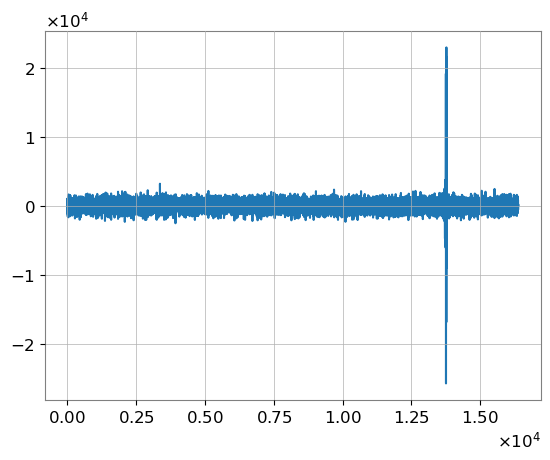

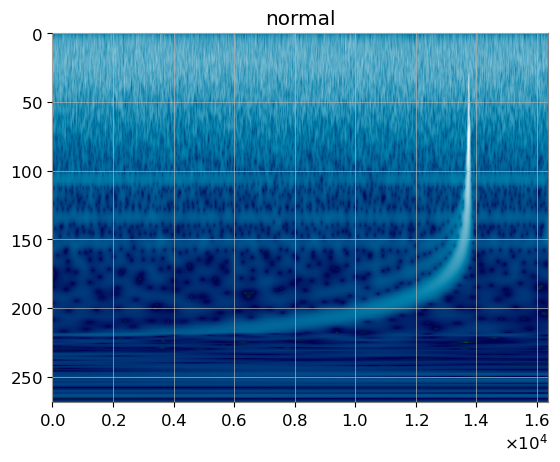

/tmp/ipykernel_352/3454454120.py:12: RuntimeWarning: divide by zero encountered in log10
  plt.imshow(np.log10(np.abs(Tx)), aspect='auto', cmap='ocean')


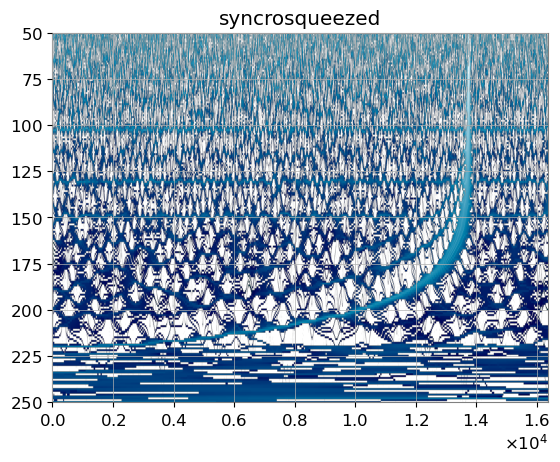

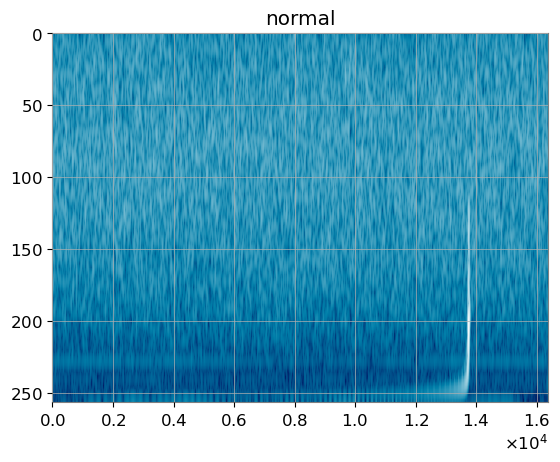

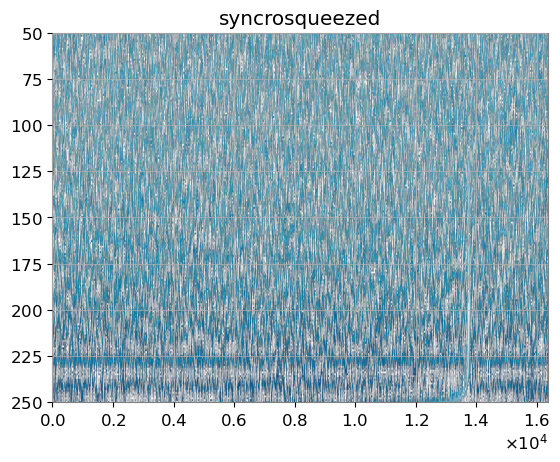

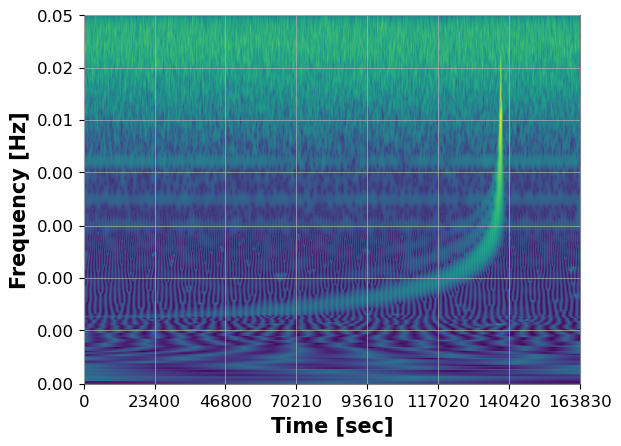

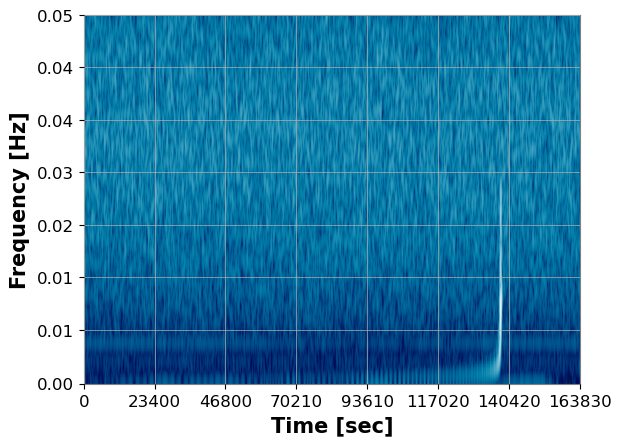

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from ssqueezepy import ssq_cwt, ssq_stft
from ssqueezepy.experimental import scale_to_freq

def viz(x, Tx, Wx):
    plt.imshow(np.log10(np.abs(Wx) ), aspect='auto', cmap='ocean')
    #plt.yscale('log')
    plt.title('normal')
    #plt.ylim(0.1,20)
    plt.show()
    plt.imshow(np.log10(np.abs(Tx)), aspect='auto', cmap='ocean')
    plt.title('syncrosqueezed')
    plt.ylim(250,50)

    #plt.yscale('log')


    plt.show()

dt = 10.0                       
fs = 1.0 / dt                   
Tobs = 2 * 24 * 3600   
df= 1/Tobs

N = 2**int(np.floor(np.log2(Tobs / dt)))
t = np.arange(N) * dt
freqs_fft = np.fft.rfftfreq(N, dt)

#%%# Define signal ####################################
x = h_mix *1e22

plt.plot(x);  plt.show()

#%%# CWT + SSQ CWT ####################################

Twx, Wx, *_ = ssq_cwt(x)
viz(x, Twx, Wx)

#%%# STFT + SSQ STFT ##################################

Tsx, Sx, *_ = ssq_stft(x)
viz(x, np.flipud(Tsx), np.flipud(Sx))

#%%# With units #######################################
from ssqueezepy import Wavelet, cwt, stft, imshow

dt = 10.0                       
fs = 1.0 / dt                   
Tobs = 2 * 24 * 3600   
df= 1/Tobs

N = 2**int(np.floor(np.log2(Tobs / dt)))
t = np.arange(N) * dt
freqs_fft = np.fft.rfftfreq(N, dt)

wavelet = Wavelet()
Wx, scales = cwt(x, wavelet)
Sx = stft(x)[::-1]

freqs_cwt = scale_to_freq(scales, wavelet, len(x), fs=fs)
freqs_stft = np.linspace(1, 0, len(Sx)) * fs/2

ikw = dict(abs=1, xticks=t, xlabel="Time [sec]", ylabel="Frequency [Hz]")
imshow(np.log10(Wx), **ikw, yticks=freqs_cwt, cmap='viridis')
imshow(np.log10(Sx), **ikw, yticks=freqs_stft, cmap= 'ocean')

/tmp/ipykernel_352/259093392.py:29: RuntimeWarning: divide by zero encountered in log10
  power_ssq = np.log10(np.abs(Twx))


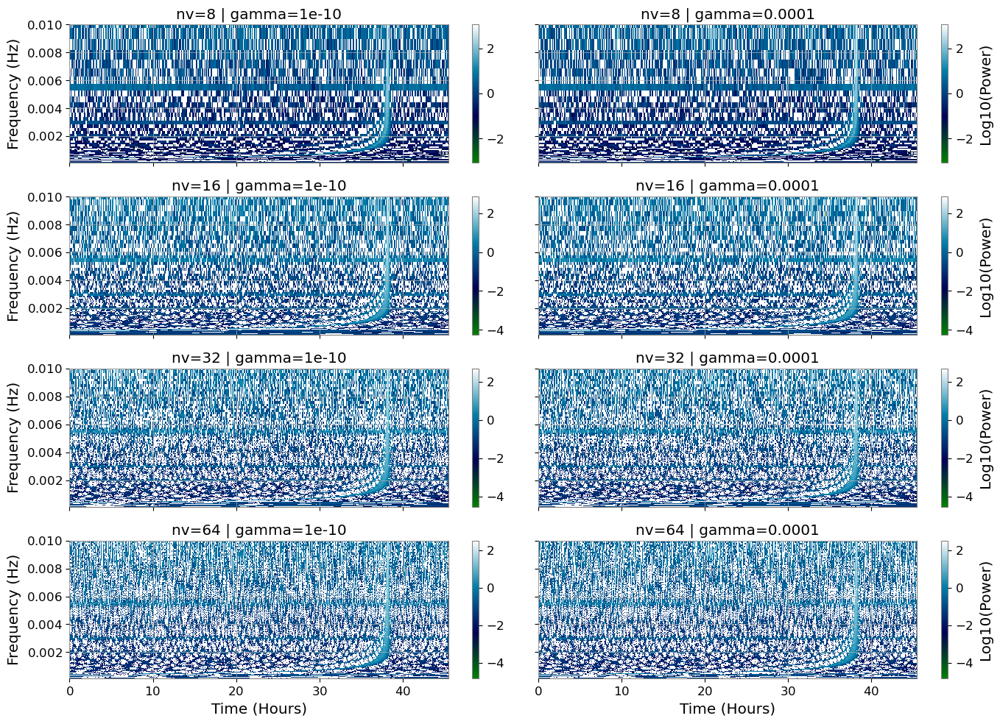

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from ssqueezepy import ssq_cwt

h_mix_scaled = np.asarray(h_mix * 1e22, dtype=np.float64)
time_hours = t / 3600.0

nv_values =[8, 16, 32, 64]
gamma_values =[1e-10, 1e-4]

fig, axes = plt.subplots(len(nv_values), len(gamma_values), figsize=(14, 10), sharex=True, sharey=True)

for i, nv in enumerate(nv_values):
    for j, gamma in enumerate(gamma_values):
        ssq_out = ssq_cwt(
            h_mix_scaled,
            wavelet='morlet',
            #scales='log',
            nv=nv,
            gamma=gamma,
            padtype='zero',
            fs=fs
        )
        
        Twx = ssq_out[0]
        ssq_freqs = ssq_out[2]
        
        freqs_mHz = ssq_freqs 
        power_ssq = np.log10(np.abs(Twx))
        
        ax = axes[i, j]
        pcm = ax.pcolormesh(time_hours, freqs_mHz, power_ssq, cmap='ocean', shading='nearest')
        
        ax.set_title(f"nv={nv} | gamma={gamma}")
        ax.set_ylim(1e-4, 1e-2)
        
        if i == len(nv_values) - 1:
            ax.set_xlabel('Time (Hours)')
        if j == 0:
            ax.set_ylabel('Frequency (Hz)')
            
        fig.colorbar(pcm, ax=ax, label='Log10(Power)' if j == len(gamma_values)-1 else '')

plt.tight_layout()
plt.show()

/tmp/ipykernel_352/2464968273.py:29: RuntimeWarning: divide by zero encountered in log10
  power_ssq = np.log10(np.abs(Twx))


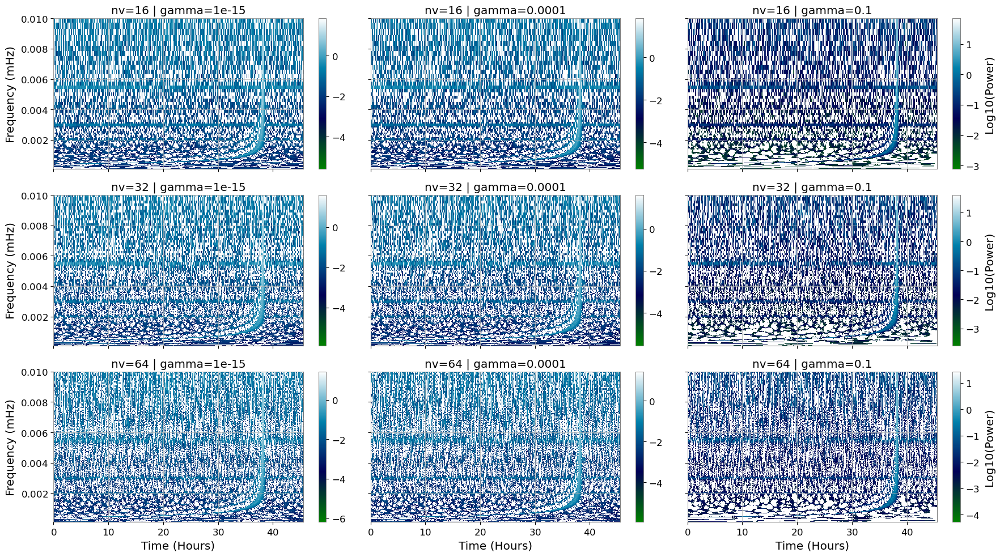

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from ssqueezepy import ssq_cwt

h_mix_scaled = np.asarray(h_mix * 1e21, dtype=np.float64)
time_hours = t / 3600.0

nv_values =[16, 32, 64]
gamma_values =[1e-15, 1e-4, 1e-1]

fig, axes = plt.subplots(len(nv_values), len(gamma_values), figsize=(18, 10), sharex=True, sharey=True)

for i, nv in enumerate(nv_values):
    for j, gamma in enumerate(gamma_values):
        ssq_out = ssq_cwt(
            h_mix_scaled,
            wavelet='morlet',
            scales='log',
            nv=nv,
            gamma=gamma,
            padtype='zero',
            fs=fs
        )
        
        Twx = ssq_out[0]
        ssq_freqs = ssq_out[2]
        
        freqs_mHz = ssq_freqs 
        power_ssq = np.log10(np.abs(Twx))
        
        ax = axes[i, j]
        pcm = ax.pcolormesh(time_hours, freqs_mHz, power_ssq, cmap='ocean', shading='nearest')
        
        ax.set_title(f"nv={nv} | gamma={gamma}")
        ax.set_ylim(1e-4, 1e-2)
        
        if i == len(nv_values) - 1:
            ax.set_xlabel('Time (Hours)')
        if j == 0:
            ax.set_ylabel('Frequency (mHz)')
            
        fig.colorbar(pcm, ax=ax, label='Log10(Power)' if j == len(gamma_values)-1 else '')

plt.tight_layout()
plt.show()

/tmp/ipykernel_352/3429218376.py:28: RuntimeWarning: divide by zero encountered in log10
  power_ssq = np.log10(np.abs(Twx))


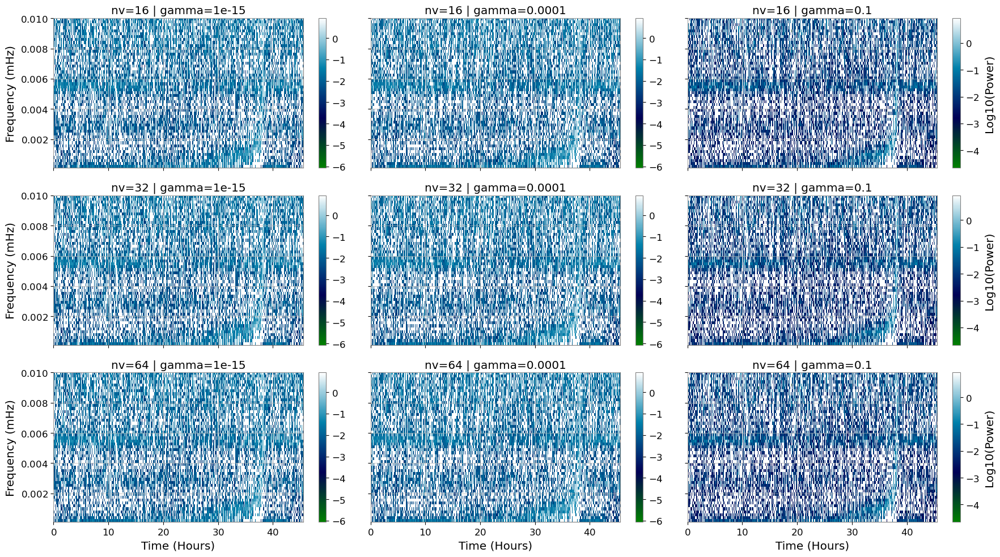

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from ssqueezepy import ssq_cwt

h_mix_scaled = np.asarray(h_mix * 1e21, dtype=np.float64)
time_hours = t / 3600.0

nv_values =[16, 32, 64]
gamma_values =[1e-15, 1e-4, 1e-1]

fig, axes = plt.subplots(len(nv_values), len(gamma_values), figsize=(18, 10), sharex=True, sharey=True)

for i, nv in enumerate(nv_values):
    for j, gamma in enumerate(gamma_values):
        ssq_out = ssq_stft(
            h_mix_scaled,
            n_fft=512,
            win_len=512,
            gamma=gamma,
            padtype='zero',
            fs=fs
        )
        
        Twx = ssq_out[0]
        ssq_freqs = ssq_out[2]
        
        freqs_mHz = ssq_freqs 
        power_ssq = np.log10(np.abs(Twx))
        
        ax = axes[i, j]
        pcm = ax.pcolormesh(time_hours, freqs_mHz, power_ssq, cmap='ocean', shading='nearest')
        
        ax.set_title(f"nv={nv} | gamma={gamma}")
        ax.set_ylim(1e-4, 1e-2)
        
        if i == len(nv_values) - 1:
            ax.set_xlabel('Time (Hours)')
        if j == 0:
            ax.set_ylabel('Frequency (mHz)')
            
        fig.colorbar(pcm, ax=ax, label='Log10(Power)' if j == len(gamma_values)-1 else '')

plt.tight_layout()
plt.show()

# PLOT I HAD IN SLIDES, EASY

Observation Window: 48.0 hours
Generation Buffer : 30.0 days
Generating massive black hole binary (MBHB)...
Generating Galactic Binaries (GBs) and Noise...
Data Generation Complete.


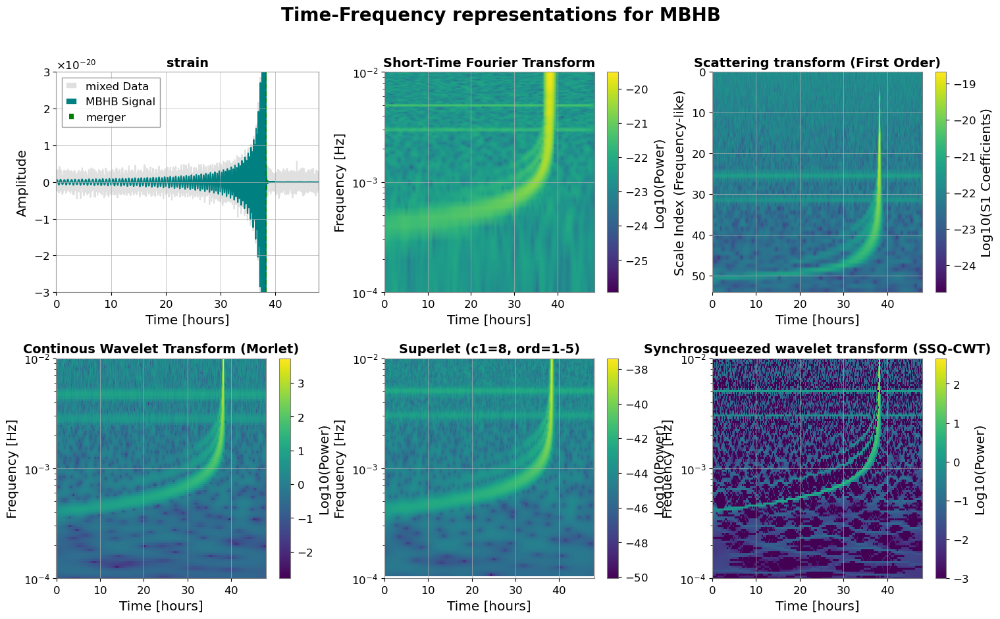

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft
import torch

# Custom imports based on your environment
import scripts.fix_cupy
from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import PC_SI
from gbgpu.gbgpu import GBGPU
from kymatio.numpy import Scattering1D
from ssqueezepy import ssq_cwt
from scripts.superlet import superlets

# ==========================================
# 1. SETUP & PARAMETERS
# ==========================================
dt = 10.0
fs = 1.0 / dt

T_obs = 48 * 3600            # 48 Hours window
N_obs = int(T_obs / dt)
t_hours = np.arange(N_obs) * dt / 3600.0

T_gen = 30 * 24 * 3600       # 30 Days generation buffer
N_gen = int(T_gen / dt)      

print(f"Observation Window: {T_obs/3600:.1f} hours")
print(f"Generation Buffer : {T_gen/86400:.1f} days")

# ==========================================
# 2. GENERATE DATA (MBHB + GBS + NOISE)
# ==========================================
print("Generating massive black hole binary (MBHB)...")
wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))
m1, m2 = 6e5, 1e6
dist = 15e3 * PC_SI * 1e6
modes =[(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

# Place merger at 80% of our 48-hour window
t_merger_in_long_buffer = T_gen - (T_obs * 0.2) 
freqs_long = np.fft.rfftfreq(N_gen, dt)

wave_long_fd = wave_gen(
    m1, m2, 0.2, 0.4, dist,
    0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, 
    t_merger_in_long_buffer, 
    t_obs_start=0.0, t_obs_end=T_gen, 
    freqs=freqs_long, modes=modes, direct=False, fill=True, length=N_gen
)[0]

# Convert to Time Domain and cut the last 48 hours
h_long_td = np.fft.irfft(wave_long_fd, n=N_gen)
h_mbhb_cut = np.atleast_2d(h_long_td)[0, -N_obs:] 

print("Generating Galactic Binaries (GBs) and Noise...")
gb = GBGPU(force_backend="cpu")
gb_params = np.array([
    [3e-22, 2e-22], [3.0e-3, 5.0e-3],[1e-17, 1e-17], 
    [0,0], [0,0],[0.5,0.5], [0,0], [0,0], [0,0]
])

gb.run_wave(*gb_params, N=N_obs, dt=dt, T=T_obs, oversample=2) 
h_gb_cut = np.zeros(N_obs)
freqs_short = np.fft.rfftfreq(N_obs, dt)

for i in range(len(gb_params[0])):
    gb_fd = np.interp(freqs_short, gb.freqs[i], gb.A[i].real) + \
            1j * np.interp(freqs_short, gb.freqs[i], gb.A[i].imag)
    h_gb_cut += np.fft.irfft(gb_fd, n=N_obs)

np.random.seed(42)
noise = np.random.normal(0, 1e-21, N_obs)

# Final Mix
h_mix = h_mbhb_cut + h_gb_cut + noise
print("Data Generation Complete.")

# ==========================================
# 3. COMPUTE REPRESENTATIONS
# ==========================================
# STFT
nperseg = 1024
f_stft, t_stft, Z_stft = stft(h_mix, fs, nperseg=nperseg, noverlap=int(nperseg*0.8))

# SCATTERING TRANSFORM
scat = Scattering1D(J=8, shape=h_mix.size, Q=8, T=1, max_order=2)
S = scat(h_mix)
S1 = S[scat.meta()['order'] == 1]

# SUPERLET
mask = (freqs_short >= 1e-4) & (freqs_short <= 10e-3)
freqs_clean = freqs_short[mask]
sl_power = np.log10(superlets(data=h_mix, fs=fs, foi=freqs_clean, c1=8, ord=(1,5)))

# SSQ-CWT
ssq_out = ssq_cwt(h_mix * 1e22, fs=fs, wavelet='morlet', scales='log', nv=16, padtype='zero')
Twx, Wx, ssq_freqs = ssq_out[0], ssq_out[1], ssq_out[2]


fig, axes = plt.subplots(2, 3, figsize=(18, 10))
plt.subplots_adjust(hspace=0.3, wspace=0.25)

merger_time_hr = (T_obs * 0.8) / 3600

axes[0,0].plot(t_hours, h_mix, color='lightgray', alpha=0.7, label='mixed Data')
axes[0,0].plot(t_hours, h_mbhb_cut, color='teal', label='MBHB Signal')
axes[0,0].axvline(merger_time_hr, color='green', linestyle='--', label='merger')
axes[0,0].set_title("strain", fontsize=14, fontweight='bold')
axes[0,0].set_xlabel("Time [hours]")
axes[0,0].set_ylabel("Amplitude")
axes[0,0].set_xlim(0, 48)
axes[0,0].set_ylim(-3e-20, 3e-20)
axes[0,0].legend(loc="upper left")


im_stft = axes[0,1].pcolormesh(t_stft/3600, f_stft, np.log10(np.abs(Z_stft) + 1e-30), shading='gouraud', cmap='viridis')
axes[0,1].set_title("Short-Time Fourier Transform", fontsize=14, fontweight='bold')
axes[0,1].set_xlabel("Time [hours]")
axes[0,1].set_ylabel("Frequency [Hz]")
axes[0,1].set_yscale('log')
axes[0,1].set_ylim(1e-4, 1e-2)

fig.colorbar(im_stft, ax=axes[0,1], label='Log10(Power)')
im_scat = axes[0,2].imshow(np.log10(S1 + 1e-30), aspect='auto', origin='lower', cmap='viridis', extent=[0, 48, 0, S1.shape[0]])

axes[0,2].set_title("Scattering transform (First Order)", fontsize=14, fontweight='bold')
axes[0,2].set_xlabel("Time [hours]")
axes[0,2].set_ylabel("Scale Index (Frequency-like)")
axes[0,2].invert_yaxis()
#axes[0,2].axvline(merger_time_hr, color='red', linestyle='--')

fig.colorbar(im_scat, ax=axes[0,2], label='Log10(S1 Coefficients)')
im_cwt = axes[1,0].pcolormesh(t_hours, ssq_freqs, np.log10(np.abs(Wx) + 1e-3), cmap='viridis', shading='nearest')
axes[1,0].set_title("Continous Wavelet Transform (Morlet)", fontsize=14, fontweight='bold')
axes[1,0].set_xlabel("Time [hours]")
axes[1,0].set_ylabel("Frequency [Hz]")
axes[1,0].set_yscale('log')
axes[1,0].set_ylim(1e-4, 1e-2)

fig.colorbar(im_cwt, ax=axes[1,0], label='Log10(Power)')
extent_sl =[0, 48, freqs_clean[0], freqs_clean[-1]]
im_sl = axes[1,1].imshow(sl_power, aspect='auto', origin='lower', extent=extent_sl, cmap='viridis')
axes[1,1].set_title("Superlet (c1=8, ord=1-5)", fontsize=14, fontweight='bold')
axes[1,1].set_xlabel("Time [hours]")
axes[1,1].set_ylabel("Frequency [Hz]")
axes[1,1].set_yscale('log')
axes[1,1].set_ylim(1e-4, 1e-2)
fig.colorbar(im_sl, ax=axes[1,1], label='Log10(Power)')

im_ssq = axes[1,2].pcolormesh(t_hours, ssq_freqs, np.log10(np.abs(Twx) + 1e-3), cmap='viridis', shading='nearest')
axes[1,2].set_title("Synchrosqueezed wavelet transform (SSQ-CWT)", fontsize=14, fontweight='bold')
axes[1,2].set_xlabel("Time [hours]")
axes[1,2].set_ylabel("Frequency [Hz]")
axes[1,2].set_yscale('log')
axes[1,2].set_ylim(1e-4, 1e-2)
fig.colorbar(im_ssq, ax=axes[1,2], label='Log10(Power)')

plt.suptitle("Time-Frequency representations for MBHB", fontsize=20, fontweight='bold', y=0.98)
plt.savefig('time_freq_repr.pdf')
plt.show()

--- 1. GENERATING DATA ---

--- 2. RUNNING BENCHMARKS ---
Computing STFT...
Computing CWT...
Computing Superlets...
Computing Scattering Transform...
Computing Q-Transform...

BENCHMARK RESULTS:
       Method  Time (s)  RAM (MB)
        STFT     0.001     0.673
CWT (Morlet)     0.132    23.730
    Superlet     6.447   225.571
Scattering1D     0.624     7.119
 Q-Transform     0.040     0.222

--- 3. GENERATING PLOTS ---


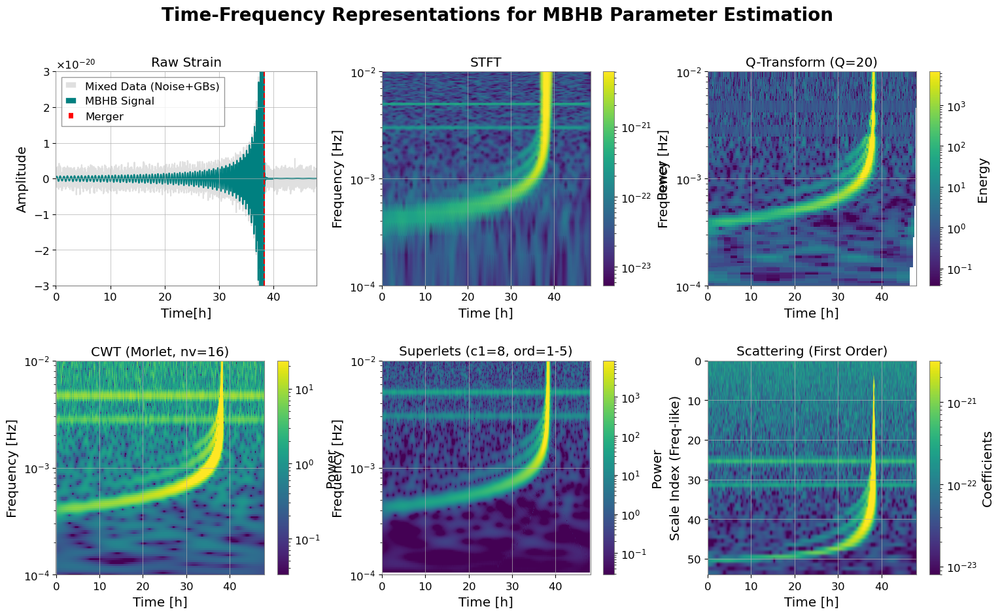

In [8]:
import time
import scripts.fix_cupy
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.collections import PolyCollection
from scipy.signal import stft
import torch

# Custom imports based on your environment
from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import PC_SI
from gbgpu.gbgpu import GBGPU
from kymatio.numpy import Scattering1D
from ssqueezepy import ssq_cwt
from scripts.superlet import superlets
from gwpy.timeseries import TimeSeries

# ==========================================
# 1. SETUP & DATA GENERATION
# ==========================================
print("--- 1. GENERATING DATA ---")
dt = 10.0
fs = 1.0 / dt
T_obs = 48 * 3600            # 48 Hours window
N_obs = int(T_obs / dt)
t_hours = np.arange(N_obs) * dt / 3600.0

T_gen = 30 * 24 * 3600       
N_gen = int(T_gen / dt)      
freqs_long = np.fft.rfftfreq(N_gen, dt)
freqs_short = np.fft.rfftfreq(N_obs, dt)

wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))
m1, m2 = 6e5, 1e6
dist = 15e3 * PC_SI * 1e6
modes =[(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]
t_merger_in_long_buffer = T_gen - (T_obs * 0.2) 

wave_long_fd = wave_gen(
    m1, m2, 0.2, 0.4, dist, 0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, 
    t_merger_in_long_buffer, t_obs_start=0.0, t_obs_end=T_gen, 
    freqs=freqs_long, modes=modes, direct=False, fill=True, length=N_gen
)[0]

h_mbhb_cut = np.fft.irfft(wave_long_fd, n=N_gen)[0, -N_obs:] 

gb = GBGPU(force_backend="cpu")
gb_params = np.array([[3e-22, 2e-22],[3.0e-3, 5.0e-3],[1e-17, 1e-17], [0,0],[0,0],[0.5,0.5], [0,0], [0,0],[0,0]])
gb.run_wave(*gb_params, N=N_obs, dt=dt, T=T_obs, oversample=2) 
h_gb_cut = np.zeros(N_obs)
for i in range(len(gb_params[0])):
    gb_fd = np.interp(freqs_short, gb.freqs[i], gb.A[i].real) + 1j * np.interp(freqs_short, gb.freqs[i], gb.A[i].imag)
    h_gb_cut += np.fft.irfft(gb_fd, n=N_obs)

np.random.seed(42)
noise = np.random.normal(0, 1e-21, N_obs)
h_mix = h_mbhb_cut + h_gb_cut + noise

# ==========================================
# 2. BENCHMARKING & COMPUTATION
# ==========================================
print("\n--- 2. RUNNING BENCHMARKS ---")
benchmarks =[]
fmin, fmax = 1e-4, 1e-2  # Standardized plot limits

def lognorm(Z):
    pos = Z[Z > 0]
    vmin = np.percentile(pos, 2) if pos.size else 1e-30
    vmax = np.percentile(Z, 99) if Z.size else 1.0
    return colors.LogNorm(vmin=max(vmin, 1e-30), vmax=max(vmax, vmin*1.01))

# --- STFT ---
print("Computing STFT...")
t0 = time.perf_counter()
f_stft, t_stft, Z_stft = stft(h_mix, fs, nperseg=1024, noverlap=int(1024*0.8))
benchmarks.append({'Method': 'STFT', 'Time (s)': time.perf_counter() - t0, 'RAM (MB)': Z_stft.nbytes / 1024**2})

# --- CWT ---
print("Computing CWT...")
t0 = time.perf_counter()
ssq_out = ssq_cwt(h_mix * 1e22, fs=fs, wavelet='morlet', scales='log', nv=16, padtype='zero')
Wx_cwt = ssq_out[1]
f_cwt = ssq_out[2]
benchmarks.append({'Method': 'CWT (Morlet)', 'Time (s)': time.perf_counter() - t0, 'RAM (MB)': Wx_cwt.nbytes / 1024**2})

# --- Superlets ---
print("Computing Superlets...")
t0 = time.perf_counter()
mask = (freqs_short >= fmin) & (freqs_short <= fmax)
freqs_sl = freqs_short[mask]
sl_power = superlets(data=h_mix * 1e22, fs=fs, foi=freqs_sl, c1=8, ord=(1,5))
benchmarks.append({'Method': 'Superlet', 'Time (s)': time.perf_counter() - t0, 'RAM (MB)': sl_power.nbytes / 1024**2})

# --- Scattering ---
print("Computing Scattering Transform...")
t0 = time.perf_counter()
scat = Scattering1D(J=8, shape=h_mix.size, Q=8, T=1, max_order=2)
S = scat(h_mix)
S1 = S[scat.meta()['order'] == 1]
benchmarks.append({'Method': 'Scattering1D', 'Time (s)': time.perf_counter() - t0, 'RAM (MB)': S1.nbytes / 1024**2})

# --- Q-Transform (GWpy) ---
print("Computing Q-Transform...")
t0 = time.perf_counter()
ts = TimeSeries(h_mix, dt=dt, t0=0)
qg = ts.q_gram(frange=(fmin, fmax), qrange=(20, 20), mismatch=0.2, snrthresh=0.0)
benchmarks.append({'Method': 'Q-Transform', 'Time (s)': time.perf_counter() - t0, 'RAM (MB)': np.asarray(qg['energy']).nbytes / 1024**2})

df_bench = pd.DataFrame(benchmarks).round(3)
print("\nBENCHMARK RESULTS:\n", df_bench.to_string(index=False))

# ==========================================
# 3. PLOTTING THE GRID
# ==========================================
print("\n--- 3. GENERATING PLOTS ---")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# 1. STRAIN
ax = axes[0,0]
ax.plot(t_hours, h_mix, color='lightgray', alpha=0.7, label='Mixed Data (Noise+GBs)')
ax.plot(t_hours, h_mbhb_cut, color='teal', label='MBHB Signal')
ax.axvline((T_obs*0.8)/3600, color='red', linestyle='--', label='Merger')
ax.set(title="Raw Strain", xlabel="Time[h]", ylabel="Amplitude", xlim=(0, 48), ylim=(-3e-20, 3e-20))
ax.legend(loc="upper left")

# 2. STFT
ax = axes[0,1]
im = ax.pcolormesh(t_stft/3600, f_stft, np.abs(Z_stft) + 1e-30, shading='gouraud', cmap='viridis', norm=lognorm(np.abs(Z_stft)))
ax.set(title="STFT", xlabel="Time [h]", ylabel="Frequency [Hz]", yscale='log', ylim=(fmin, fmax))
fig.colorbar(im, ax=ax, label='Power')

# 3. Q-TRANSFORM
ax = axes[0,2]
tc, fc, dur, bw, en = np.asarray(qg['time']), np.asarray(qg['frequency']), np.asarray(qg['duration']), np.asarray(qg['bandwidth']), np.asarray(qg['energy'])
verts = [[((tc[k]-dur[k]/2)/3600., fc[k]-bw[k]/2), ((tc[k]+dur[k]/2)/3600., fc[k]-bw[k]/2), 
          ((tc[k]+dur[k]/2)/3600., fc[k]+bw[k]/2), ((tc[k]-dur[k]/2)/3600., fc[k]+bw[k]/2)] for k in range(len(tc))]
coll = PolyCollection(verts, array=en, cmap='viridis', norm=lognorm(en), edgecolors='none', rasterized=True)
ax.add_collection(coll)
ax.set(title="Q-Transform (Q=20)", xlabel="Time [h]", ylabel="Frequency [Hz]", yscale='log', ylim=(fmin, fmax), xlim=(0, 48))
fig.colorbar(coll, ax=ax, label='Energy')

# 4. CWT
ax = axes[1,0]
im = ax.pcolormesh(t_hours, f_cwt, np.abs(Wx_cwt), cmap='viridis', shading='auto', norm=lognorm(np.abs(Wx_cwt)), rasterized=True)
ax.set(title="CWT (Morlet, nv=16)", xlabel="Time [h]", ylabel="Frequency [Hz]", yscale='log', ylim=(fmin, fmax))
fig.colorbar(im, ax=ax, label='Power')

# 5. SUPERLET
ax = axes[1,1]
im = ax.imshow(sl_power, aspect='auto', origin='lower', extent=[0, 48, freqs_sl[0], freqs_sl[-1]], cmap='viridis', norm=lognorm(sl_power))
ax.set(title="Superlets (c1=8, ord=1-5)", xlabel="Time [h]", ylabel="Frequency [Hz]", yscale='log', ylim=(fmin, fmax))
fig.colorbar(im, ax=ax, label='Power')

# 6. SCATTERING
ax = axes[1,2]
im = ax.imshow(S1 + 1e-30, aspect='auto', origin='lower', cmap='viridis', extent=[0, 48, 0, S1.shape[0]], norm=lognorm(S1))
ax.set(title="Scattering (First Order)", xlabel="Time [h]", ylabel="Scale Index (Freq-like)")
ax.invert_yaxis()
fig.colorbar(im, ax=ax, label='Coefficients')

plt.suptitle("Time-Frequency Representations for MBHB Parameter Estimation", fontsize=20, fontweight='bold', y=0.98)
plt.savefig('time_freq_benchmark.pdf', bbox_inches='tight', dpi=150)
plt.show()

Observation Window: 48.0 hours
Generation Buffer : 30.0 days
Generating massive black hole binary (MBHB)...
Generating Galactic Binaries (GBs) and Noise...
Data Generation Complete.

--- RUNNING BENCHMARKS ---

BENCHMARK RESULTS:
       Method  Time (s)  RAM (MB)
        STFT     0.001     0.673
Scattering1D     0.635     7.119
   Superlets     6.547   225.571
   CWT / SSQ     0.125    23.730

--- GENERATING PLOTS ---


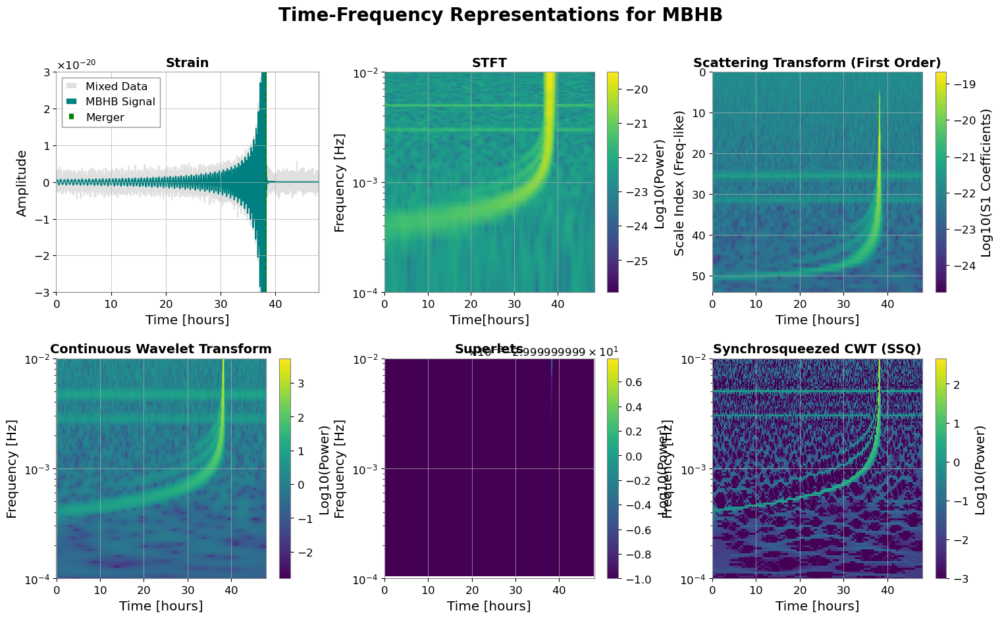

In [6]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import stft
import torch

# Custom imports based on your environment
import scripts.fix_cupy
from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import PC_SI
from gbgpu.gbgpu import GBGPU
from kymatio.numpy import Scattering1D
from ssqueezepy import ssq_cwt
from scripts.superlet import superlets

# ==========================================
# 1. SETUP & DATA GENERATION
# ==========================================
dt = 10.0
fs = 1.0 / dt

T_obs = 48 * 3600            # 48 Hours window
N_obs = int(T_obs / dt)
t_hours = np.arange(N_obs) * dt / 3600.0

T_gen = 30 * 24 * 3600       # 30 Days generation buffer
N_gen = int(T_gen / dt)      

print(f"Observation Window: {T_obs/3600:.1f} hours")
print(f"Generation Buffer : {T_gen/86400:.1f} days")

print("Generating massive black hole binary (MBHB)...")
wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))
m1, m2 = 6e5, 1e6
dist = 15e3 * PC_SI * 1e6
modes =[(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)]

# Place merger at 80% of our 48-hour window
t_merger_in_long_buffer = T_gen - (T_obs * 0.2) 
freqs_long = np.fft.rfftfreq(N_gen, dt)

wave_long_fd = wave_gen(
    m1, m2, 0.2, 0.4, dist,
    0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, 
    t_merger_in_long_buffer, 
    t_obs_start=0.0, t_obs_end=T_gen, 
    freqs=freqs_long, modes=modes, direct=False, fill=True, length=N_gen
)[0]

# Convert to Time Domain and cut the last 48 hours (Fixed slice logic)
h_long_td = np.fft.irfft(wave_long_fd, n=N_gen)
h_mbhb_cut = np.atleast_2d(h_long_td)[0, -N_obs:] 

print("Generating Galactic Binaries (GBs) and Noise...")
gb = GBGPU(force_backend="cpu")
gb_params = np.array([
    [3e-22, 2e-22],[3.0e-3, 5.0e-3],[1e-17, 1e-17], 
    [0,0], [0,0],[0.5,0.5], [0,0],[0,0], [0,0]
])

gb.run_wave(*gb_params, N=N_obs, dt=dt, T=T_obs, oversample=2) 
h_gb_cut = np.zeros(N_obs)
freqs_short = np.fft.rfftfreq(N_obs, dt)

for i in range(len(gb_params[0])):
    gb_fd = np.interp(freqs_short, gb.freqs[i], gb.A[i].real) + \
            1j * np.interp(freqs_short, gb.freqs[i], gb.A[i].imag)
    h_gb_cut += np.fft.irfft(gb_fd, n=N_obs)

np.random.seed(42)
noise = np.random.normal(0, 1e-21, N_obs)

# Final Mix
h_mix = h_mbhb_cut + h_gb_cut + noise
print("Data Generation Complete.")

# ==========================================
# 2. COMPUTE REPRESENTATIONS & BENCHMARK
# ==========================================
print("\n--- RUNNING BENCHMARKS ---")
benchmarks =[]

# --- STFT ---
t0 = time.perf_counter()
nperseg = 1024
f_stft, t_stft, Z_stft = stft(h_mix, fs, nperseg=nperseg, noverlap=int(nperseg*0.8))
benchmarks.append({'Method': 'STFT', 'Time (s)': time.perf_counter() - t0, 'RAM (MB)': Z_stft.nbytes / 1024**2})

# --- SCATTERING TRANSFORM ---
t0 = time.perf_counter()
scat = Scattering1D(J=8, shape=h_mix.size, Q=8, T=1, max_order=2)
S = scat(h_mix)
S1 = S[scat.meta()['order'] == 1]
benchmarks.append({'Method': 'Scattering1D', 'Time (s)': time.perf_counter() - t0, 'RAM (MB)': S1.nbytes / 1024**2})

# --- SUPERLET ---
t0 = time.perf_counter()
mask = (freqs_short >= 1e-4) & (freqs_short <= 10e-3)
freqs_clean = freqs_short[mask]
sl_power = np.log10(superlets(data=h_mix, fs=fs, foi=freqs_clean, c1=8, ord=(1,5)) + 1e-30)
benchmarks.append({'Method': 'Superlets', 'Time (s)': time.perf_counter() - t0, 'RAM (MB)': sl_power.nbytes / 1024**2})

# --- SSQ-CWT ---
t0 = time.perf_counter()
ssq_out = ssq_cwt(h_mix * 1e22, fs=fs, wavelet='morlet', scales='log', nv=16, padtype='zero')
Twx, Wx, ssq_freqs = ssq_out[0], ssq_out[1], ssq_out[2]
benchmarks.append({'Method': 'CWT / SSQ', 'Time (s)': time.perf_counter() - t0, 'RAM (MB)': Wx.nbytes / 1024**2})

# Display the Benchmark Table
df_bench = pd.DataFrame(benchmarks).round(3)
print("\nBENCHMARK RESULTS:\n", df_bench.to_string(index=False))

# ==========================================
# 3. PLOTTING THE GRID
# ==========================================
print("\n--- GENERATING PLOTS ---")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
plt.subplots_adjust(hspace=0.3, wspace=0.25)

merger_time_hr = (T_obs * 0.8) / 3600

# 1. STRAIN
axes[0,0].plot(t_hours, h_mix, color='lightgray', alpha=0.7, label='Mixed Data')
axes[0,0].plot(t_hours, h_mbhb_cut, color='teal', label='MBHB Signal')
axes[0,0].axvline(merger_time_hr, color='green', linestyle='--', label='Merger')
axes[0,0].set_title("Strain", fontsize=14, fontweight='bold')
axes[0,0].set_xlabel("Time [hours]")
axes[0,0].set_ylabel("Amplitude")
axes[0,0].set_xlim(0, 48)
axes[0,0].set_ylim(-3e-20, 3e-20)
axes[0,0].legend(loc="upper left")

# 2. STFT
im_stft = axes[0,1].pcolormesh(t_stft/3600, f_stft, np.log10(np.abs(Z_stft) + 1e-30), shading='gouraud', cmap='viridis')
axes[0,1].set_title("STFT", fontsize=14, fontweight='bold')
axes[0,1].set_xlabel("Time[hours]")
axes[0,1].set_ylabel("Frequency [Hz]")
axes[0,1].set_yscale('log')
axes[0,1].set_ylim(1e-4, 1e-2)
fig.colorbar(im_stft, ax=axes[0,1], label='Log10(Power)')

# 3. SCATTERING
im_scat = axes[0,2].imshow(np.log10(S1 + 1e-30), aspect='auto', origin='lower', cmap='viridis', extent=[0, 48, 0, S1.shape[0]])
axes[0,2].set_title("Scattering Transform (First Order)", fontsize=14, fontweight='bold')
axes[0,2].set_xlabel("Time [hours]")
axes[0,2].set_ylabel("Scale Index (Freq-like)")
axes[0,2].invert_yaxis()
fig.colorbar(im_scat, ax=axes[0,2], label='Log10(S1 Coefficients)')

# 4. CWT
im_cwt = axes[1,0].pcolormesh(t_hours, ssq_freqs, np.log10(np.abs(Wx) + 1e-3), cmap='viridis', shading='nearest')
axes[1,0].set_title("Continuous Wavelet Transform", fontsize=14, fontweight='bold')
axes[1,0].set_xlabel("Time [hours]")
axes[1,0].set_ylabel("Frequency [Hz]")
axes[1,0].set_yscale('log')
axes[1,0].set_ylim(1e-4, 1e-2)
fig.colorbar(im_cwt, ax=axes[1,0], label='Log10(Power)')

# 5. SUPERLET
extent_sl =[0, 48, freqs_clean[0], freqs_clean[-1]]
im_sl = axes[1,1].imshow(sl_power, aspect='auto', origin='lower', extent=extent_sl, cmap='viridis')
axes[1,1].set_title("Superlets", fontsize=14, fontweight='bold')
axes[1,1].set_xlabel("Time [hours]")
axes[1,1].set_ylabel("Frequency [Hz]")
axes[1,1].set_yscale('log')
axes[1,1].set_ylim(1e-4, 1e-2)
fig.colorbar(im_sl, ax=axes[1,1], label='Log10(Power)')

# 6. SSQ-CWT
im_ssq = axes[1,2].pcolormesh(t_hours, ssq_freqs, np.log10(np.abs(Twx) + 1e-3), cmap='viridis', shading='nearest')
axes[1,2].set_title("Synchrosqueezed CWT (SSQ)", fontsize=14, fontweight='bold')
axes[1,2].set_xlabel("Time [hours]")
axes[1,2].set_ylabel("Frequency [Hz]")
axes[1,2].set_yscale('log')
axes[1,2].set_ylim(1e-4, 1e-2)
fig.colorbar(im_ssq, ax=axes[1,2], label='Log10(Power)')

plt.suptitle("Time-Frequency Representations for MBHB", fontsize=20, fontweight='bold', y=0.98)
plt.savefig('time_freq_repr.pdf', bbox_inches='tight')
plt.show()

--- 1. GENERATING DATA ---

--- 2. RUNNING BENCHMARKS ---

BENCHMARK RESULTS:
       Method  Time (s)  RAM (MB)
        STFT     0.002     0.673
CWT (Morlet)     0.177    23.730
   Superlets     6.728   225.571
Scattering1D     0.675     7.119
 GWpy Q-gram     0.046     0.222

--- 3. GENERATING PLOTS ---


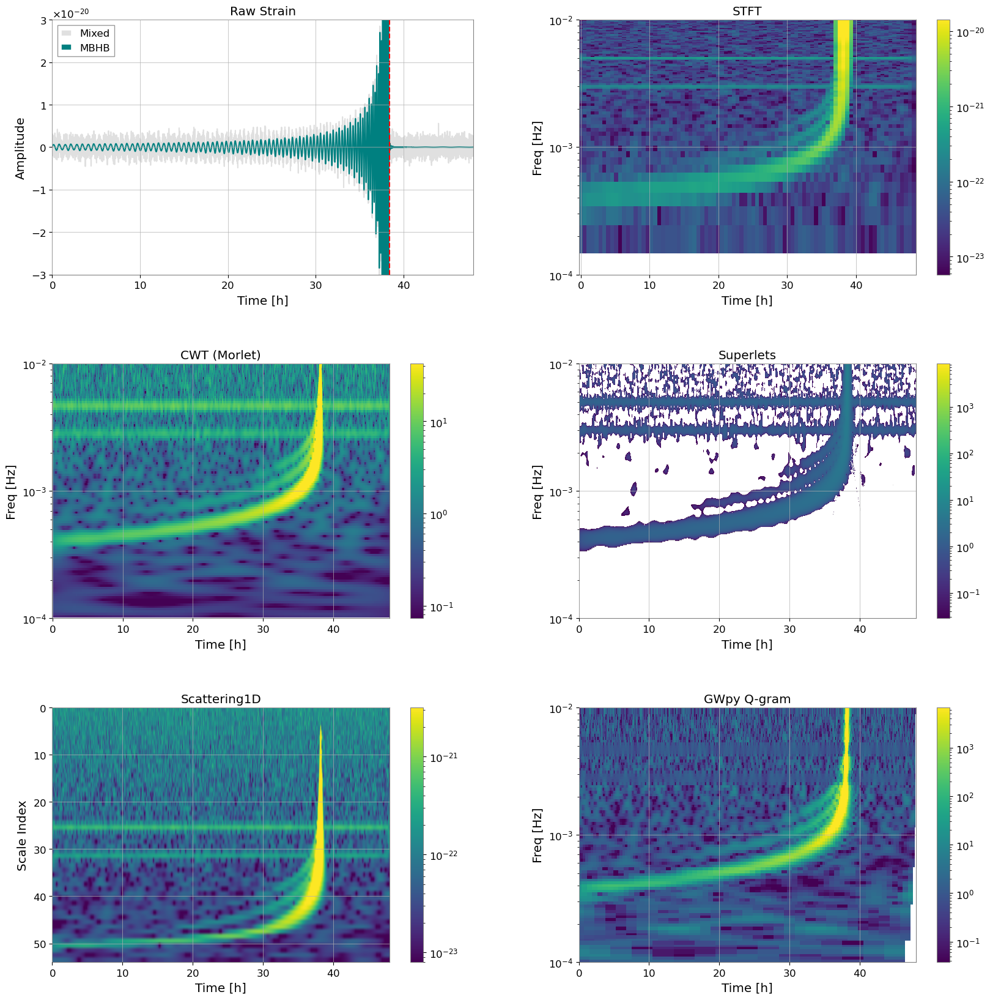

In [16]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.collections import PolyCollection
from scipy.signal import stft

# Custom imports
from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import PC_SI
from gbgpu.gbgpu import GBGPU
from kymatio.numpy import Scattering1D
from ssqueezepy import ssq_cwt
from scripts.superlet import superlets
from gwpy.timeseries import TimeSeries
#from qptransform import QpTransform
#from ltft.timeserie import Timeserie

# ==========================================
# 1. SETUP & DATA GENERATION
# ==========================================
print("--- 1. GENERATING DATA ---")
dt = 10.0
fs = 1.0 / dt
T_obs = 48 * 3600
N_obs = int(T_obs / dt)
t_arr = np.arange(N_obs) * dt
t_hours = t_arr / 3600.0

T_gen = 30 * 24 * 3600       
N_gen = int(T_gen / dt)      
freqs_long = np.fft.rfftfreq(N_gen, dt)
freqs_short = np.fft.rfftfreq(N_obs, dt)
fmin, fmax = 1e-4, 1e-2

wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))
t_merger_in_long_buffer = T_gen - (T_obs * 0.2) 

wave_long_fd = wave_gen(
    6e5, 1e6, 0.2, 0.4, 15e3 * PC_SI * 1e6, 0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, 
    t_merger_in_long_buffer, t_obs_start=0.0, t_obs_end=T_gen, 
    freqs=freqs_long, modes=[(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)], direct=False, fill=True, length=N_gen
)[0]

h_mbhb_cut = np.fft.irfft(wave_long_fd, n=N_gen)[0, -N_obs:] 

gb = GBGPU(force_backend="cpu")
gb_params = np.array([[3e-22, 2e-22],[3.0e-3, 5.0e-3],[1e-17, 1e-17], [0,0],[0,0],[0.5,0.5], [0,0], [0,0],[0,0]])
gb.run_wave(*gb_params, N=N_obs, dt=dt, T=T_obs, oversample=2) 
h_gb_cut = np.zeros(N_obs)
for i in range(len(gb_params[0])):
    gb_fd = np.interp(freqs_short, gb.freqs[i], gb.A[i].real) + 1j * np.interp(freqs_short, gb.freqs[i], gb.A[i].imag)
    h_gb_cut += np.fft.irfft(gb_fd, n=N_obs)

np.random.seed(42)
noise = np.random.normal(0, 1e-21, N_obs)
h_mix = h_mbhb_cut + h_gb_cut + noise

# ==========================================
# 2. BENCHMARKING & COMPUTATION
# ==========================================
print("\n--- 2. RUNNING BENCHMARKS ---")
benchmarks =[]

# --- STFT ---
t0 = time.perf_counter()
f_stft, t_stft, Z_stft = stft(h_mix, fs, nperseg=1024, noverlap=int(1024*0.8))
benchmarks.append({'Method': 'STFT', 'Time (s)': time.perf_counter()-t0, 'RAM (MB)': Z_stft.nbytes / 1024**2})

# --- CWT (ssqueezepy) ---
t0 = time.perf_counter()
ssq_out = ssq_cwt(h_mix * 1e22, fs=fs, wavelet='morlet', scales='log', nv=16, padtype='zero')
Twx, Wx_cwt, f_cwt = ssq_out[0], ssq_out[1], ssq_out[2]
benchmarks.append({'Method': 'CWT (Morlet)', 'Time (s)': time.perf_counter()-t0, 'RAM (MB)': Wx_cwt.nbytes / 1024**2})

# --- Superlets ---
t0 = time.perf_counter()
freqs_sl = freqs_short[(freqs_short >= fmin) & (freqs_short <= fmax)]
sl_power = np.log10(superlets(data=h_mix * 1e22, fs=fs, foi=freqs_sl, c1=8, ord=(1,5)) + 1e-30)
benchmarks.append({'Method': 'Superlets', 'Time (s)': time.perf_counter()-t0, 'RAM (MB)': sl_power.nbytes / 1024**2})

# --- Scattering ---
t0 = time.perf_counter()
scat = Scattering1D(J=8, shape=h_mix.size, Q=8, T=1, max_order=2)
S = scat(h_mix)
S1 = S[scat.meta()['order'] == 1]
benchmarks.append({'Method': 'Scattering1D', 'Time (s)': time.perf_counter()-t0, 'RAM (MB)': S1.nbytes / 1024**2})

# --- GWpy Q-gram ---
t0 = time.perf_counter()
qg = TimeSeries(h_mix, dt=dt, t0=0).q_gram(frange=(fmin, fmax), qrange=(20, 20), mismatch=0.2, snrthresh=0.0)
benchmarks.append({'Method': 'GWpy Q-gram', 'Time (s)': time.perf_counter()-t0, 'RAM (MB)': np.asarray(qg['energy']).nbytes / 1024**2})

# # --- QpTransform ---
# t0 = time.perf_counter()
# qp = QpTransform(data=h_mix, times=t_arr, whiten=False, frange=(fmin, fmax), qrange=(20, 20), prange=(0, 0), filmethod=None)
# qp_data = np.asarray(qp.qpspecgram.value)
# benchmarks.append({'Method': 'qptransform', 'Time (s)': time.perf_counter()-t0, 'RAM (MB)': qp_data.nbytes / 1024**2})

# # --- LTFT DWILT ---
# t0 = time.perf_counter()
# s_exp = 9
# n_keep = (len(h_mix) // (4 * 2**s_exp)) * (4 * 2**s_exp)
# ltft_out = Timeserie(h_mix[:n_keep], dt=dt, t0=0).dwilt(s=s_exp, wtype='hann', q=8)
# ltft_data = np.abs(ltft_out.data)**2
# benchmarks.append({'Method': 'LTFT (Hann)', 'Time (s)': time.perf_counter()-t0, 'RAM (MB)': ltft_data.nbytes / 1024**2})

df_bench = pd.DataFrame(benchmarks).round(3)
print("\nBENCHMARK RESULTS:\n", df_bench.to_string(index=False))

# ==========================================
# 3. PLOTTING THE GRID
# ==========================================
print("\n--- 3. GENERATING PLOTS ---")
def lognorm(Z):
    pos = Z[Z > 0]
    vmin, vmax = np.percentile(pos, 2) if pos.size else 1e-30, np.percentile(Z, 99) if Z.size else 1.0
    return colors.LogNorm(vmin=max(vmin, 1e-30), vmax=max(vmax, vmin*1.01))

def plot_std(ax, T, F, P, title):
    if P.shape[0] == T.size and P.shape[1] == F.size: P = P.T
    m = (F >= fmin) & (F <= fmax)
    F, P = F[m], P[m, :]
    if P.shape[1] > 600: P, T = P[:, ::P.shape[1]//600], T[::P.shape[1]//600]
    im = ax.pcolormesh(T, F, P + 1e-30, shading='auto', cmap='viridis', norm=lognorm(P), rasterized=True)
    ax.set(title=title, yscale='log', ylim=(fmin, fmax), xlabel="Time [h]", ylabel="Freq [Hz]")
    return im

fig, axes = plt.subplots(3, 2, figsize=(20, 20))
plt.subplots_adjust(hspace=0.35, wspace=0.25)
axes = axes.flatten()

# 1. Strain
axes[0].plot(t_hours, h_mix, color='lightgray', alpha=0.7, label='Mixed')
axes[0].plot(t_hours, h_mbhb_cut, color='teal', label='MBHB')
axes[0].axvline((T_obs*0.8)/3600, color='red', linestyle='--')
axes[0].set(title="Raw Strain", xlabel="Time [h]", ylabel="Amplitude", xlim=(0, 48), ylim=(-3e-20, 3e-20))
axes[0].legend(loc="upper left")

# 2. STFT
fig.colorbar(plot_std(axes[1], t_stft/3600, f_stft, np.abs(Z_stft), "STFT"), ax=axes[1])

# 3. CWT
fig.colorbar(plot_std(axes[2], t_hours, f_cwt, np.abs(Wx_cwt), "CWT (Morlet)"), ax=axes[2])

# 4. Superlet
im = axes[3].imshow(sl_power, aspect='auto', origin='lower', extent=[0, 48, freqs_sl[0], freqs_sl[-1]], cmap='viridis', norm=lognorm(10**sl_power))
axes[3].set(title="Superlets", xlabel="Time [h]", ylabel="Freq [Hz]", yscale='log', ylim=(fmin, fmax))
fig.colorbar(im, ax=axes[3])

# 5. Scattering
im = axes[4].imshow(S1+1e-30, aspect='auto', origin='lower', cmap='viridis', extent=[0, 48, 0, S1.shape[0]], norm=lognorm(S1))
axes[4].set(title="Scattering1D", xlabel="Time [h]", ylabel="Scale Index")
axes[4].invert_yaxis()
fig.colorbar(im, ax=axes[4])

# 6. GWpy Q-gram
tc, fc, dur, bw, en = [np.asarray(qg[k]) for k in ['time','frequency','duration','bandwidth','energy']]
verts = [[((tc[k]-dur[k]/2)/3600., fc[k]-bw[k]/2), ((tc[k]+dur[k]/2)/3600., fc[k]-bw[k]/2), ((tc[k]+dur[k]/2)/3600., fc[k]+bw[k]/2), ((tc[k]-dur[k]/2)/3600., fc[k]+bw[k]/2)] for k in range(len(tc))]
coll = PolyCollection(verts, array=en, cmap='viridis', norm=lognorm(en), edgecolors='none', rasterized=True)
axes[5].add_collection(coll)
axes[5].set(title="GWpy Q-gram", xlabel="Time [h]", ylabel="Freq [Hz]", yscale='log', ylim=(fmin, fmax), xlim=(0, 48))
fig.colorbar(coll, ax=axes[5])

# # 7. qptransform
# t_qp, f_qp = qp.series.times.value - qp.series.times.value[0], qp.qpspecgram.frequencies.value
# fig.colorbar(plot_std(axes[6], t_qp/3600, f_qp, qp_data, "QpTransform"), ax=axes[6])

# # 8. LTFT
# t_ltft, f_ltft = (ltft_out.t0 + np.arange(ltft_out.ntbins)*ltft_out.dtbin)/3600.0, ltft_out.f0 + np.arange(ltft_out.nfbins)*ltft_out.dfbin
# fig.colorbar(plot_std(axes[7], t_ltft, f_ltft, ltft_data, "LTFT (Hann)"), ax=axes[7])

# plt.suptitle("Time-Frequency Representation Benchmarks", fontsize=22, fontweight='bold', y=0.98)
# plt.savefig('tf_benchmarks_ultimate.pdf', bbox_inches='tight', dpi=150)
# plt.show()

In [2]:

import scripts.fix_cupy
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib import colors
from scipy.signal import stft

# Custom imports
from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import PC_SI
from gbgpu.gbgpu import GBGPU
from kymatio.numpy import Scattering1D
from ssqueezepy import ssq_cwt
# from superlet import superlets

# Import nnAudio for the GPU-accelerated Q-Transform
from nnAudio.features.cqt import CQT1992v2

# ==========================================
# 1. SETUP & DATA GENERATION
# ==========================================
print("--- 1. GENERATING DATA ---")
dt = 10.0
fs = 1.0 / dt
T_obs = 48 * 3600
N_obs = int(T_obs / dt)
t_arr = np.arange(N_obs) * dt
t_hours = t_arr / 3600.0

T_gen = 30 * 24 * 3600       
N_gen = int(T_gen / dt)      
freqs_long = np.fft.rfftfreq(N_gen, dt)
freqs_short = np.fft.rfftfreq(N_obs, dt)
fmin, fmax = 1e-4, 1e-2

wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))
t_merger_in_long_buffer = T_gen - (T_obs * 0.2) 

wave_long_fd = wave_gen(
    6e5, 1e6, 0.2, 0.4, 15e3 * PC_SI * 1e6, 0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, 
    t_merger_in_long_buffer, t_obs_start=0.0, t_obs_end=T_gen, 
    freqs=freqs_long, modes=[(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)], direct=False, fill=True, length=N_gen
)[0]

h_mbhb_cut = np.fft.irfft(wave_long_fd, n=N_gen)[0, -N_obs:] 

gb = GBGPU(force_backend="cpu")
gb_params = np.array([[3e-22, 2e-22],[3.0e-3, 5.0e-3],[1e-17, 1e-17], [0,0],[0,0],[0.5,0.5], [0,0], [0,0],[0,0]])
gb.run_wave(*gb_params, N=N_obs, dt=dt, T=T_obs, oversample=2) 
h_gb_cut = np.zeros(N_obs)
for i in range(len(gb_params[0])):
    gb_fd = np.interp(freqs_short, gb.freqs[i], gb.A[i].real) + 1j * np.interp(freqs_short, gb.freqs[i], gb.A[i].imag)
    h_gb_cut += np.fft.irfft(gb_fd, n=N_obs)

np.random.seed(42)
noise = np.random.normal(0, 1e-21, N_obs)
h_mix = h_mbhb_cut + h_gb_cut + noise

# ==========================================
# 2. BENCHMARKING & COMPUTATION
# ==========================================
print("\n--- 2. RUNNING BENCHMARKS ---")
benchmarks =[]

# --- STFT ---
t0 = time.perf_counter()
f_stft, t_stft, Z_stft = stft(h_mix, fs, nperseg=1024, noverlap=int(1024*0.8))
benchmarks.append({'Method': 'STFT', 'Time (s)': time.perf_counter()-t0, 'RAM (MB)': Z_stft.nbytes / 1024**2})

# --- CWT (ssqueezepy) ---
t0 = time.perf_counter()
ssq_out = ssq_cwt(h_mix * 1e22, fs=fs, wavelet='morlet', scales='log', nv=16, padtype='zero')
Twx, Wx_cwt, f_cwt = ssq_out[0], ssq_out[1], ssq_out[2]
benchmarks.append({'Method': 'CWT (Morlet)', 'Time (s)': time.perf_counter()-t0, 'RAM (MB)': Wx_cwt.nbytes / 1024**2})

# # --- Superlets ---
# t0 = time.perf_counter()
# freqs_sl = freqs_short[(freqs_short >= fmin) & (freqs_short <= fmax)]
# sl_power = np.log10(superlets(data=h_mix * 1e22, fs=fs, foi=freqs_sl, c1=8, ord=(1,5)) + 1e-30)
# benchmarks.append({'Method': 'Superlets', 'Time (s)': time.perf_counter()-t0, 'RAM (MB)': sl_power.nbytes / 1024**2})

# --- Scattering ---
t0 = time.perf_counter()
scat = Scattering1D(J=8, shape=h_mix.size, Q=8, T=1, max_order=2)
S = scat(h_mix)
S1 = S[scat.meta()['order'] == 1]
benchmarks.append({'Method': 'Scattering1D', 'Time (s)': time.perf_counter()-t0, 'RAM (MB)': S1.nbytes / 1024**2})

# --- nnAudio CQT (Q-transform) ---
t0 = time.perf_counter()
device = "cuda" if torch.cuda.is_available() else "cpu"
cqt_layer = CQT1992v2(
    sr=fs, fmin=fmin, fmax=fmax, 
    hop_length=128, bins_per_octave=16, 
    output_format="Magnitude", verbose=False
).to(device)

h_mix_tensor = torch.tensor(h_mix * 1e22, dtype=torch.float32, device=device).unsqueeze(0)
cqt_out = cqt_layer(h_mix_tensor)[0].cpu().numpy()

# Extract frequencies and time axes for plotting
f_cqt = cqt_layer.frequencies
t_cqt = np.arange(cqt_out.shape[1]) * (128 * dt) / 3600.0 # Convert to hours
benchmarks.append({'Method': 'nnAudio CQT', 'Time (s)': time.perf_counter()-t0, 'RAM (MB)': cqt_out.nbytes / 1024**2})

df_bench = pd.DataFrame(benchmarks).round(3)
print("\nBENCHMARK RESULTS:\n", df_bench.to_string(index=False))

# ==========================================
# 3. PLOTTING THE GRID
# ==========================================
print("\n--- 3. GENERATING PLOTS ---")
def lognorm(Z):
    pos = Z[Z > 0]
    vmin, vmax = np.percentile(pos, 2) if pos.size else 1e-30, np.percentile(Z, 99) if Z.size else 1.0
    return colors.LogNorm(vmin=max(vmin, 1e-30), vmax=max(vmax, vmin*1.01))

def plot_std(ax, T, F, P, title):
    if P.shape[0] == T.size and P.shape[1] == F.size: P = P.T
    m = (F >= fmin) & (F <= fmax)
    F, P = F[m], P[m, :]
    if P.shape[1] > 600: P, T = P[:, ::P.shape[1]//600], T[::P.shape[1]//600]
    im = ax.pcolormesh(T, F, P + 1e-30, shading='auto', cmap='viridis', norm=lognorm(P), rasterized=True)
    ax.set(title=title, yscale='log', ylim=(fmin, fmax), xlabel="Time [h]", ylabel="Freq [Hz]")
    return im

fig, axes = plt.subplots(3, 2, figsize=(20, 20))
plt.subplots_adjust(hspace=0.35, wspace=0.25)
axes = axes.flatten()

# 1. Strain
axes[0].plot(t_hours, h_mix, color='lightgray', alpha=0.7, label='Mixed')
axes[0].plot(t_hours, h_mbhb_cut, color='teal', label='MBHB')
axes[0].axvline((T_obs*0.8)/3600, color='red', linestyle='--')
axes[0].set(title="Raw Strain", xlabel="Time [h]", ylabel="Amplitude", xlim=(0, 48), ylim=(-3e-20, 3e-20))
axes[0].legend(loc="upper left")

# 2. STFT
fig.colorbar(plot_std(axes[1], t_stft/3600, f_stft, np.abs(Z_stft), "STFT"), ax=axes[1])

# 3. CWT
fig.colorbar(plot_std(axes[2], t_hours, f_cwt, np.abs(Wx_cwt), "CWT (Morlet)"), ax=axes[2])

# # 4. Superlet
# im = axes[3].imshow(sl_power, aspect='auto', origin='lower', extent=[0, 48, freqs_sl[0], freqs_sl[-1]], cmap='viridis', norm=lognorm(10**sl_power))
# axes[3].set(title="Superlets", xlabel="Time[h]", ylabel="Freq [Hz]", yscale='log', ylim=(fmin, fmax))
# fig.colorbar(im, ax=axes[3])

# 5. Scattering
im = axes[4].imshow(S1+1e-30, aspect='auto', origin='lower', cmap='viridis', extent=[0, 48, 0, S1.shape[0]], norm=lognorm(S1))
axes[4].set(title="Scattering1D", xlabel="Time [h]", ylabel="Scale Index")
axes[4].invert_yaxis()
fig.colorbar(im, ax=axes[4])

# 6. nnAudio CQT
fig.colorbar(plot_std(axes[5], t_cqt, f_cqt, cqt_out, "nnAudio CQT (Q-Transform)"), ax=axes[5])

plt.suptitle("Time-Frequency Representation Benchmarks", fontsize=22, fontweight='bold', y=0.98)
plt.show()

LOG: [fix_cupy] Attempting to patch CuPy...
LOG: [fix_cupy] Patching cupy.cuda.runtime._getLocalRuntimeVersion
LOG: [fix_cupy] Patch complete.
--- 1. GENERATING DATA ---


AttributeError: 'numpy.ndarray' object has no attribute 'get'

--- 1. GENERATING DATA ---

--- 2. RUNNING BENCHMARKS ---

--- 3. GENERATING PLOTS ---
-> Strain build time: 0.006 s

FINAL BENCHMARK RESULTS (Compute + Plot Setup):

      Method  Compute Time (s)  RAM (MB)  Plot Build (s)
        STFT             0.001     0.673           0.018
CWT (Morlet)             0.128    23.730           0.029
   Superlets             7.073   225.571           2.125
Scattering1D             0.673     7.119           0.044
 GWpy Q-gram             0.045     0.222           0.999

--- 4. RENDERING PLOTS ---
-> Total Matplotlib RENDER time: 3.884 seconds


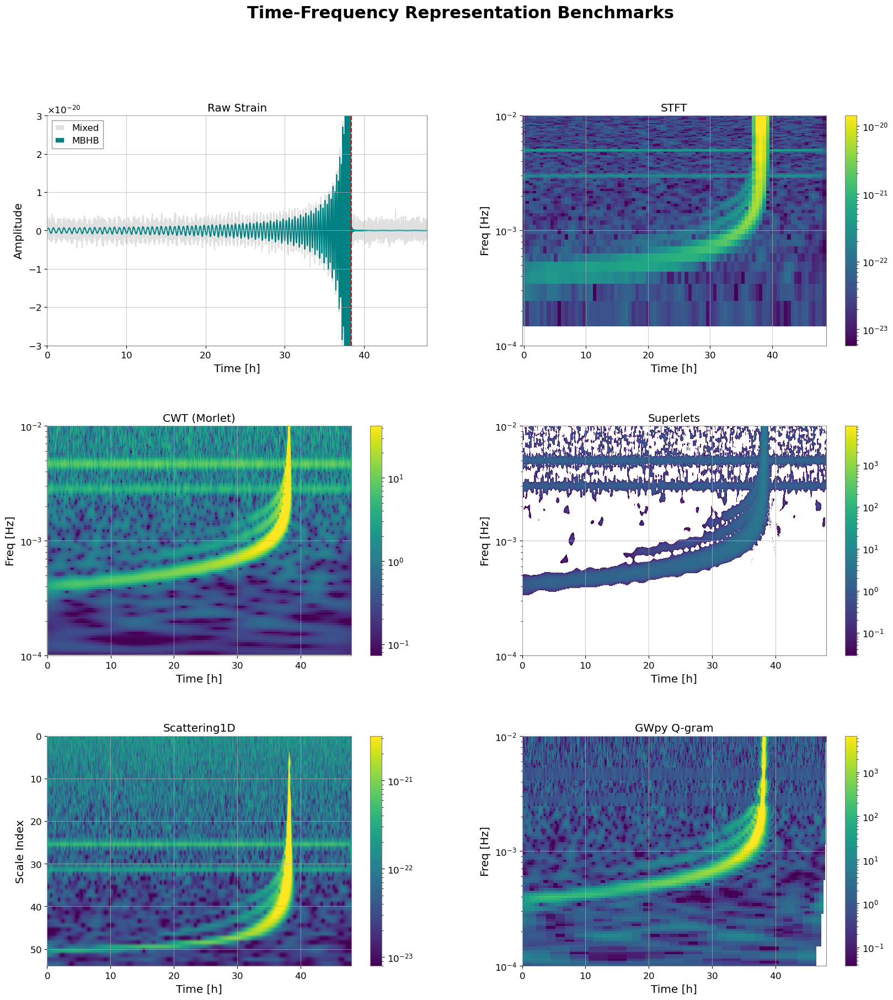

In [17]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.collections import PolyCollection
from scipy.signal import stft

# Custom imports
from bbhx.waveformbuild import BBHWaveformFD
from bbhx.utils.constants import PC_SI
from gbgpu.gbgpu import GBGPU
from kymatio.numpy import Scattering1D
from ssqueezepy import ssq_cwt
from scripts.superlet import superlets
from gwpy.timeseries import TimeSeries
#from qptransform import QpTransform
#from ltft.timeserie import Timeserie

# ==========================================
# 1. SETUP & DATA GENERATION
# ==========================================
print("--- 1. GENERATING DATA ---")
dt = 10.0
fs = 1.0 / dt
T_obs = 48 * 3600
N_obs = int(T_obs / dt)
t_arr = np.arange(N_obs) * dt
t_hours = t_arr / 3600.0

T_gen = 30 * 24 * 3600       
N_gen = int(T_gen / dt)      
freqs_long = np.fft.rfftfreq(N_gen, dt)
freqs_short = np.fft.rfftfreq(N_obs, dt)
fmin, fmax = 1e-4, 1e-2

wave_gen = BBHWaveformFD(amp_phase_kwargs=dict(run_phenomd=False))
t_merger_in_long_buffer = T_gen - (T_obs * 0.2) 

wave_long_fd = wave_gen(
    6e5, 1e6, 0.2, 0.4, 15e3 * PC_SI * 1e6, 0.0, 0.0, np.pi/3, np.pi/5, np.pi/4, np.pi/6, 
    t_merger_in_long_buffer, t_obs_start=0.0, t_obs_end=T_gen, 
    freqs=freqs_long, modes=[(2,2), (2,1), (3,3), (3,2), (4,4), (4,3)], direct=False, fill=True, length=N_gen
)[0]

h_mbhb_cut = np.fft.irfft(wave_long_fd, n=N_gen)[0, -N_obs:] 

gb = GBGPU(force_backend="cpu")
gb_params = np.array([[3e-22, 2e-22],[3.0e-3, 5.0e-3],[1e-17, 1e-17], [0,0],[0,0],[0.5,0.5], [0,0], [0,0],[0,0]])
gb.run_wave(*gb_params, N=N_obs, dt=dt, T=T_obs, oversample=2) 
h_gb_cut = np.zeros(N_obs)
for i in range(len(gb_params[0])):
    gb_fd = np.interp(freqs_short, gb.freqs[i], gb.A[i].real) + 1j * np.interp(freqs_short, gb.freqs[i], gb.A[i].imag)
    h_gb_cut += np.fft.irfft(gb_fd, n=N_obs)

np.random.seed(42)
noise = np.random.normal(0, 1e-21, N_obs)
h_mix = h_mbhb_cut + h_gb_cut + noise

# ==========================================
# 2. BENCHMARKING & COMPUTATION
# ==========================================
print("\n--- 2. RUNNING BENCHMARKS ---")
benchmarks =[]

# --- STFT ---
t0 = time.perf_counter()
f_stft, t_stft, Z_stft = stft(h_mix, fs, nperseg=1024, noverlap=int(1024*0.8))
benchmarks.append({'Method': 'STFT', 'Compute Time (s)': time.perf_counter()-t0, 'RAM (MB)': Z_stft.nbytes / 1024**2})

# --- CWT (ssqueezepy) ---
t0 = time.perf_counter()
ssq_out = ssq_cwt(h_mix * 1e22, fs=fs, wavelet='morlet', scales='log', nv=16, padtype='zero')
Twx, Wx_cwt, f_cwt = ssq_out[0], ssq_out[1], ssq_out[2]
benchmarks.append({'Method': 'CWT (Morlet)', 'Compute Time (s)': time.perf_counter()-t0, 'RAM (MB)': Wx_cwt.nbytes / 1024**2})

# --- Superlets ---
t0 = time.perf_counter()
freqs_sl = freqs_short[(freqs_short >= fmin) & (freqs_short <= fmax)]
sl_power = np.log10(superlets(data=h_mix * 1e22, fs=fs, foi=freqs_sl, c1=8, ord=(1,5)) + 1e-30)
benchmarks.append({'Method': 'Superlets', 'Compute Time (s)': time.perf_counter()-t0, 'RAM (MB)': sl_power.nbytes / 1024**2})

# --- Scattering ---
t0 = time.perf_counter()
scat = Scattering1D(J=8, shape=h_mix.size, Q=8, T=1, max_order=2)
S = scat(h_mix)
S1 = S[scat.meta()['order'] == 1]
benchmarks.append({'Method': 'Scattering1D', 'Compute Time (s)': time.perf_counter()-t0, 'RAM (MB)': S1.nbytes / 1024**2})

# --- GWpy Q-gram ---
t0 = time.perf_counter()
qg = TimeSeries(h_mix, dt=dt, t0=0).q_gram(frange=(fmin, fmax), qrange=(20, 20), mismatch=0.2, snrthresh=0.0)
benchmarks.append({'Method': 'GWpy Q-gram', 'Compute Time (s)': time.perf_counter()-t0, 'RAM (MB)': np.asarray(qg['energy']).nbytes / 1024**2})


# ==========================================
# 3. PLOTTING THE GRID (BUILD TIMES)
# ==========================================
print("\n--- 3. GENERATING PLOTS ---")
def lognorm(Z):
    pos = Z[Z > 0]
    vmin, vmax = np.percentile(pos, 2) if pos.size else 1e-30, np.percentile(Z, 99) if Z.size else 1.0
    return colors.LogNorm(vmin=max(vmin, 1e-30), vmax=max(vmax, vmin*1.01))

def plot_std(ax, T, F, P, title):
    if P.shape[0] == T.size and P.shape[1] == F.size: P = P.T
    m = (F >= fmin) & (F <= fmax)
    F, P = F[m], P[m, :]
    if P.shape[1] > 600: P, T = P[:, ::P.shape[1]//600], T[::P.shape[1]//600]
    im = ax.pcolormesh(T, F, P + 1e-30, shading='auto', cmap='viridis', norm=lognorm(P), rasterized=True)
    ax.set(title=title, yscale='log', ylim=(fmin, fmax), xlabel="Time [h]", ylabel="Freq [Hz]")
    return im

fig, axes = plt.subplots(3, 2, figsize=(20, 20))
plt.subplots_adjust(hspace=0.35, wspace=0.25)
axes = axes.flatten()

# 1. Strain (not included in the main benchmark table)
t0 = time.perf_counter()
axes[0].plot(t_hours, h_mix, color='lightgray', alpha=0.7, label='Mixed')
axes[0].plot(t_hours, h_mbhb_cut, color='teal', label='MBHB')
axes[0].axvline((T_obs*0.8)/3600, color='red', linestyle='--')
axes[0].set(title="Raw Strain", xlabel="Time [h]", ylabel="Amplitude", xlim=(0, 48), ylim=(-3e-20, 3e-20))
axes[0].legend(loc="upper left")
print(f"-> Strain build time: {time.perf_counter()-t0:.3f} s")

# 2. STFT
t0 = time.perf_counter()
fig.colorbar(plot_std(axes[1], t_stft/3600, f_stft, np.abs(Z_stft), "STFT"), ax=axes[1])
benchmarks[0]['Plot Build (s)'] = time.perf_counter() - t0

# 3. CWT
t0 = time.perf_counter()
fig.colorbar(plot_std(axes[2], t_hours, f_cwt, np.abs(Wx_cwt), "CWT (Morlet)"), ax=axes[2])
benchmarks[1]['Plot Build (s)'] = time.perf_counter() - t0

# 4. Superlet
t0 = time.perf_counter()
im = axes[3].imshow(sl_power, aspect='auto', origin='lower', extent=[0, 48, freqs_sl[0], freqs_sl[-1]], cmap='viridis', norm=lognorm(10**sl_power))
axes[3].set(title="Superlets", xlabel="Time [h]", ylabel="Freq [Hz]", yscale='log', ylim=(fmin, fmax))
fig.colorbar(im, ax=axes[3])
benchmarks[2]['Plot Build (s)'] = time.perf_counter() - t0

# 5. Scattering
t0 = time.perf_counter()
im = axes[4].imshow(S1+1e-30, aspect='auto', origin='lower', cmap='viridis', extent=[0, 48, 0, S1.shape[0]], norm=lognorm(S1))
axes[4].set(title="Scattering1D", xlabel="Time [h]", ylabel="Scale Index")
axes[4].invert_yaxis()
fig.colorbar(im, ax=axes[4])
benchmarks[3]['Plot Build (s)'] = time.perf_counter() - t0

# 6. GWpy Q-gram
t0 = time.perf_counter()
tc, fc, dur, bw, en = [np.asarray(qg[k]) for k in['time','frequency','duration','bandwidth','energy']]
verts = [[((tc[k]-dur[k]/2)/3600., fc[k]-bw[k]/2), ((tc[k]+dur[k]/2)/3600., fc[k]-bw[k]/2), ((tc[k]+dur[k]/2)/3600., fc[k]+bw[k]/2), ((tc[k]-dur[k]/2)/3600., fc[k]+bw[k]/2)] for k in range(len(tc))]
coll = PolyCollection(verts, array=en, cmap='viridis', norm=lognorm(en), edgecolors='none', rasterized=True)
axes[5].add_collection(coll)
axes[5].set(title="GWpy Q-gram", xlabel="Time [h]", ylabel="Freq [Hz]", yscale='log', ylim=(fmin, fmax), xlim=(0, 48))
fig.colorbar(coll, ax=axes[5])
benchmarks[4]['Plot Build (s)'] = time.perf_counter() - t0


# Print Final Merged Benchmark Table
df_bench = pd.DataFrame(benchmarks).round(3)
print("\nFINAL BENCHMARK RESULTS (Compute + Plot Setup):\n")
print(df_bench.to_string(index=False))

# ==========================================
# 4. RENDERING & SAVING
# ==========================================
print("\n--- 4. RENDERING PLOTS ---")
plt.suptitle("Time-Frequency Representation Benchmarks", fontsize=22, fontweight='bold', y=0.98)

t0_render = time.perf_counter()

# fig.canvas.draw() forces matplotlib to actually render the graphics to memory
# This tells us the exact time it takes to process the pixels/polygons before showing.
fig.canvas.draw() 

render_time = time.perf_counter() - t0_render
print(f"-> Total Matplotlib RENDER time: {render_time:.3f} seconds")

# plt.savefig('tf_benchmarks_ultimate.pdf', bbox_inches='tight', dpi=150)
plt.show()